# DMart Store Inventory & Supplier Replenishment System
## SQL Developer Colab

| Field | Value |
|---|---|
| Company | DMart |
| Industry | Retail |
| Product Area | Store Inventory & Supplier Replenishment Operations |
| Role | SQL Developer |
| Runtime | Google Colab |
| Database | SQLite |
| Main Skills | Relational design, internal API consumption, SQL reporting, transaction integrity, workflow automation, safe engineering practices |

DMart retail operations need one SQL-led control system for products, stores, warehouses, suppliers, purchase orders, goods receipts, inventory movements, stock exceptions, and daily replenishment recommendations. This notebook keeps SQL at the centre while Python prepares the runtime, Dataset, internal API, SQLite database, validation, and diagrams.

# How to Use This Notebook
1. In Google Colab choose **Runtime -> Run all**.
2. Allow the prebuilt setup to create the deterministic Dataset, internal API, SQLite database, validation helpers, and inventory-control exceptions.
3. Wait until the output prints **SETUP COMPLETE**.
4. Begin only after the large **SQL DEVELOPER WORK STARTS HERE** heading.
5. Edit only cells marked **SQL DEVELOPER WORKSPACE**.
6. Compare each result with its **Expected Output** section and use the visible validator status.
7. Unanswered workspaces are designed to return **Needs Review** rather than a red runtime error.
8. Mutable API records and transaction activity records are reset before use so the notebook can be rerun safely.

# 1. RUN THIS SETUP ONCE - DO NOT EDIT

## 1.1 Environment and Project Folder
Prebuilt runtime imports, project paths, display settings, deterministic seed, and diagram dependency checks.

In [ ]:
import os, sys, json, random, sqlite3, subprocess, shutil, threading, time
from pathlib import Path
from collections import defaultdict
from datetime import date, datetime, timedelta
import pandas as pd
import requests

SEED=20260812
REVIEW_DATE="2026-08-01"
REVIEW_CUTOFF="2026-08-02 00:00:00"
random.seed(SEED)

# Keep everything local to the active runtime.
RUNTIME_BASE=Path("/content") if Path("/content").exists() else Path("/mnt/data")
PROJECT_DIR=RUNTIME_BASE/"dmart_inventory_replenishment_runtime"
RAW_DIR=PROJECT_DIR/"raw_json"
PROJECT_DIR.mkdir(parents=True,exist_ok=True)
RAW_DIR.mkdir(parents=True,exist_ok=True)

# Graphviz is used only for text-driven diagrams.
try:
    import graphviz
except ImportError:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","graphviz"])
if shutil.which("dot") is None:
    subprocess.check_call(["apt-get","update","-qq"])
    subprocess.check_call(["apt-get","install","-y","-qq","graphviz"])

pd.set_option("display.max_columns",20)
pd.set_option("display.width",140)
print("Environment ready.")
print("Runtime directory:",PROJECT_DIR)
print("Deterministic seed:",SEED)

Environment ready.
Runtime directory: /content/dmart_inventory_replenishment_runtime
Deterministic seed: 20260812


## 1.2 Dataset
Create the complete deterministic retail Dataset with controlled supplier, receipt, movement, stock, damage, and transfer conditions.

In [ ]:
def generate_dataset(seed=20260812):
    rng=random.Random(seed)
    cities=["Mumbai","Pune","Bengaluru","Hyderabad","Ahmedabad","Chennai","Delhi","Nagpur"]
    regions={"Mumbai":"West","Pune":"West","Ahmedabad":"West","Nagpur":"West","Bengaluru":"South","Hyderabad":"South","Chennai":"South","Delhi":"North"}
    categories=["Staples","Dairy","Beverages","Personal Care","Home Care","Packaged Food","Snacks","Household"]
    category_nouns={
        "Staples":["Rice","Flour","Cooking Oil"],
        "Dairy":["Milk","Curd","Paneer"],
        "Beverages":["Juice","Tea","Coffee"],
        "Personal Care":["Soap","Shampoo","Toothpaste"],
        "Home Care":["Floor Cleaner","Dishwash","Surface Cleaner"],
        "Packaged Food":["Biscuits","Noodles","Cereal"],
        "Snacks":["Chips","Namkeen","Snack Mix"],
        "Household":["Detergent","Tissues","Garbage Bags"],
    }
    locations=[]
    for i in range(1,21):
        lt="STORE" if i<=15 else "WAREHOUSE"
        city=cities[(i-1)%len(cities)]
        locations.append({"location_id":f"LOC{i:03d}","location_name":f"DMart {city} {'Store' if lt=='STORE' else 'Warehouse'} {((i-1)//len(cities))+1}","location_type":lt,"city":city,"region":regions[city],"status":"MAINTENANCE" if i==14 else "ACTIVE"})
    suppliers=[]
    prefixes=["Aarav","Bharat","Crest","Delta","Evergreen","Freshway","Global","Harvest","Indus","Jupiter","Kaveri","Lotus","Metro"]
    suffixes=["Foods","Consumer","Supplies","Distributors","Trading","Products","Wholesale"]
    for i in range(1,26):
        suppliers.append({"supplier_id":f"SUP{i:03d}","supplier_name":f"{prefixes[(i*3)%len(prefixes)]} {suffixes[(i*5)%len(suffixes)]} {i:02d}","city":cities[(i*2)%len(cities)],"lead_time_days":2+(i%7),"status":"ON_HOLD" if i in {9,21} else "ACTIVE","rating":round(3.1+((i*17)%19)/10,1)})
    products=[]
    adjectives=["Premium","Classic","Fresh","Everyday","Family","Value","Select","Essential","Smart","Pure"]
    for i in range(1,121):
        supplier=suppliers[(i*7)%len(suppliers)]
        reorder=24+((i*11)%42)
        category=categories[(i*5)%len(categories)]
        noun=category_nouns[category][i % len(category_nouns[category])]
        products.append({"product_id":f"P{i:04d}","product_name":f"{adjectives[i%len(adjectives)]} {noun} {i:03d}","category":category,"unit_cost":round(18+((i*37)%430)+((i%7)*0.35),2),"reorder_level":reorder,"target_stock":reorder+45+((i*13)%90),"preferred_supplier_id":supplier["supplier_id"],"status":"DISCONTINUED" if i in {119,120} else "ACTIVE"})
    by_sup=defaultdict(list)
    for p in products: by_sup[p["preferred_supplier_id"]].append(p)
    pos=[]; items=[]; receipts=[]; item_seq=0; rseq=1
    start=date(2026,7,1)
    for i in range(1,361):
        sup=suppliers[(i*7)%len(suppliers)]; dest=locations[(i*11)%len(locations)]
        od=start+timedelta(days=(i*5)%27); ed=od+timedelta(days=sup["lead_time_days"]+((i%3)-1))
        cancelled=(i%37==0); poid=f"PO{i:05d}"
        cand=by_sup[sup["supplier_id"]] or products
        n=3+(i%4); chosen=rng.sample(cand,k=min(n,len(cand)))
        if len(chosen)<n:
            extras=[p for p in products if p not in chosen]
            chosen += rng.sample(extras,n-len(chosen))
        total=0
        for p in chosen:
            item_seq+=1
            qty=24+((i*17+int(p["product_id"][1:]))%118)
            cost=round(p["unit_cost"]*(0.96+((i+item_seq)%7)*0.01),2)
            line=round(qty*cost,2); total+=line
            items.append({"po_id":poid,"product_id":p["product_id"],"ordered_qty":qty,"unit_cost":cost,"line_value":line})
            if cancelled: continue
            missing=item_seq%29==0
            short=(item_seq%19==0 and not missing)
            over=(item_seq%23==0 and not missing and not short)
            split=(item_seq%17==0 and not missing)
            late=(item_seq%31==0 and not missing)
            if missing: continue
            received=max(1,qty-(4+item_seq%15)) if short else qty+(2+item_seq%9) if over else qty
            rd=ed+timedelta(days=(3+item_seq%4) if late else (item_seq%3)-1)
            dmg=min(received,2+item_seq%6) if item_seq%41==0 else 0
            parts=[received]
            if split and received>8:
                a=max(1,int(received*.55)); parts=[a,received-a]
            dleft=dmg
            for j,pq in enumerate(parts,1):
                dq=min(dleft,pq); dleft-=dq
                receipts.append({"receipt_id":f"GR{rseq:06d}","po_id":poid,"product_id":p["product_id"],"receipt_date":(rd+timedelta(days=j-1)).isoformat(),"received_qty":pq,"damaged_qty":dq,"supplier_reference":f"SR-{i:05d}-{p['product_id']}-{j}","receipt_status":"PARTIAL" if len(parts)>1 and j==1 else "ACCEPTED"})
                rseq+=1
        pos.append({"po_id":poid,"supplier_id":sup["supplier_id"],"destination_location_id":dest["location_id"],"order_date":od.isoformat(),"expected_date":ed.isoformat(),"po_status":"CANCELLED" if cancelled else "APPROVED","total_order_value":round(total,2)})
    for idx in range(140,len(receipts),211):
        receipts[idx]["supplier_reference"]=receipts[idx-1]["supplier_reference"]
    rec_by=defaultdict(int)
    for r in receipts:
        if r["receipt_date"]<=REVIEW_DATE:
            rec_by[(r["po_id"],r["product_id"])]+=r["received_qty"]
    items_by=defaultdict(list)
    for x in items: items_by[x["po_id"]].append(x)
    for po in pos:
        if po["po_status"]=="CANCELLED": continue
        ls=items_by[po["po_id"]]
        anyr=any(rec_by[(x["po_id"],x["product_id"])]>0 for x in ls)
        allr=all(rec_by[(x["po_id"],x["product_id"])]>=x["ordered_qty"] for x in ls)
        po["po_status"]="RECEIVED" if allr else "PARTIALLY_RECEIVED" if anyr else "APPROVED"
    moves=[]; mseq=1
    def add(pid,frm,to,typ,when,qty,ref,status="POSTED"):
        nonlocal mseq
        moves.append({"movement_id":f"MOV{mseq:07d}","product_id":pid,"from_location_id":frm,"to_location_id":to,"movement_type":typ,"movement_date":when,"quantity":int(qty),"reference_id":ref,"status":status}); mseq+=1
    for pi,p in enumerate(products,1):
        for li,l in enumerate(locations,1):
            base=p["target_stock"]+((pi*7+li*11)%61)-20
            if (pi+2*li)%19==0: base=max(8,p["reorder_level"]-15)
            add(p["product_id"],None,l["location_id"],"OPENING_STOCK","2026-06-30 23:59:00",max(5,base),f"OPEN-{p['product_id']}-{l['location_id']}")
    po_lookup={x["po_id"]:x for x in pos}
    for r in receipts:
        dest=po_lookup[r["po_id"]]["destination_location_id"]
        add(r["product_id"],None,dest,"GOODS_RECEIPT",r["receipt_date"]+" 10:00:00",r["received_qty"],r["receipt_id"])
        if r["damaged_qty"]: add(r["product_id"],dest,None,"DAMAGE",r["receipt_date"]+" 12:00:00",r["damaged_qty"],"DMG-"+r["receipt_id"])
    stores=[x for x in locations if x["location_type"]=="STORE" and x["status"]=="ACTIVE"]
    wh=[x for x in locations if x["location_type"]=="WAREHOUSE"]
    for i in range(1,3001):
        p=products[(i*13+i//11)%118]; l=stores[(i*7)%len(stores)]
        when=datetime(2026,7,1)+timedelta(minutes=(i*337)%(31*24*60))
        status="POSTED" if i%29 else "PENDING" if i%58 else "CANCELLED"
        add(p["product_id"],l["location_id"],None,"SALE",when.strftime("%Y-%m-%d %H:%M:%S"),1+((i*5+int(p["product_id"][1:]))%12),f"SALE-{i:06d}",status)
    for i in range(1,261):
        p=products[(i*17)%118]; l=stores[(i*3)%len(stores)]
        when=datetime(2026,7,2)+timedelta(minutes=(i*821)%(29*24*60))
        add(p["product_id"],None,l["location_id"],"CUSTOMER_RETURN",when.strftime("%Y-%m-%d %H:%M:%S"),1+i%4,f"RET-{i:05d}")
    for i in range(1,451):
        p=products[(i*19)%118]; src=wh[(i*2)%len(wh)]; dst=stores[(i*5)%len(stores)]
        when=datetime(2026,7,1)+timedelta(minutes=(i*1499)%(31*24*60))
        add(p["product_id"],src["location_id"],dst["location_id"],"TRANSFER",when.strftime("%Y-%m-%d %H:%M:%S"),5+i%26,f"TRF-{i:05d}","PENDING" if i%73==0 else "POSTED")
    for i in range(1,221):
        p=products[(i*23)%118]; l=locations[(i*9)%len(locations)]
        when=datetime(2026,7,3)+timedelta(minutes=(i*577)%(28*24*60))
        q=26+i%12 if i%37==0 else 1+i%8
        add(p["product_id"],l["location_id"],None,"DAMAGE",when.strftime("%Y-%m-%d %H:%M:%S"),q,f"DMG-OPS-{i:05d}")
    for i in range(1,81):
        p=products[(i*31)%118]; l=locations[(i*13)%len(locations)]
        when=datetime(2026,7,5)+timedelta(minutes=(i*911)%(25*24*60))
        if i%2: add(p["product_id"],None,l["location_id"],"ADJUSTMENT",when.strftime("%Y-%m-%d %H:%M:%S"),1+i%5,f"ADJ-SYS-{i:05d}")
        else: add(p["product_id"],l["location_id"],None,"ADJUSTMENT",when.strftime("%Y-%m-%d %H:%M:%S"),1+i%4,f"ADJ-SYS-{i:05d}")
    net=defaultdict(int)
    for m in moves:
        if m["status"]!="POSTED" or m["movement_date"]>=REVIEW_CUTOFF: continue
        if m["to_location_id"]: net[(m["product_id"],m["to_location_id"])]+=m["quantity"]
        if m["from_location_id"]: net[(m["product_id"],m["from_location_id"])]-=m["quantity"]
    opens={(m["product_id"],m["to_location_id"]):m for m in moves if m["movement_type"]=="OPENING_STOCK"}
    for key,val in list(net.items()):
        if val<3:
            opens[key]["quantity"] += 3-val
    return {"products":products,"locations":locations,"suppliers":suppliers,"purchase_orders":pos,"purchase_order_items":items,"goods_receipts":receipts,"inventory_movements":moves}

dataset=generate_dataset(SEED)
dataset_counts=pd.DataFrame([{"Dataset resource":k,"Rows":len(v)} for k,v in dataset.items()])
display(dataset_counts)
print("Dataset created deterministically inside the runtime.")

,Dataset resource,Rows
0,products,120
1,locations,20
2,suppliers,25
3,purchase_orders,360
4,purchase_order_items,1620
5,goods_receipts,1616
6,inventory_movements,8063


Dataset created deterministically inside the runtime.


## 1.3 Temporary Internal API
Start a local internal API inside the active runtime. The SQL Developer consumes these endpoints and does not build the server.

In [ ]:
import json, threading, urllib.parse
from http.server import ThreadingHTTPServer, BaseHTTPRequestHandler

API_RESOURCES = {
    "products": [dict(x) for x in dataset["products"]],
    "locations": [dict(x) for x in dataset["locations"]],
    "suppliers": [dict(x) for x in dataset["suppliers"]],
    "purchase_orders": [dict(x) for x in dataset["purchase_orders"]],
    "purchase_order_items": [dict(x) for x in dataset["purchase_order_items"]],
    "goods_receipts": [dict(x) for x in dataset["goods_receipts"]],
    "inventory_movements": [dict(x) for x in dataset["inventory_movements"]],
}

API_MOVEMENT_FIELDS = [
    "movement_id","product_id","from_location_id","to_location_id",
    "movement_type","movement_date","quantity","reference_id","status"
]

PRACTICE_BASELINES = {
    "API-MOV-PUT-001": {
        "movement_id":"API-MOV-PUT-001","product_id":"P0002","from_location_id":"LOC016",
        "to_location_id":"LOC001","movement_type":"TRANSFER","movement_date":"2026-07-31 14:00:00",
        "quantity":12,"reference_id":"TRF-API-PUT-BASE","status":"PENDING"
    },
    "API-MOV-PATCH-001": {
        "movement_id":"API-MOV-PATCH-001","product_id":"P0003","from_location_id":"LOC002",
        "to_location_id":None,"movement_type":"DAMAGE","movement_date":"2026-07-31 14:15:00",
        "quantity":4,"reference_id":"DMG-API-PATCH-BASE","status":"PENDING"
    },
    "API-MOV-DELETE-001": {
        "movement_id":"API-MOV-DELETE-001","product_id":"P0004","from_location_id":"LOC017",
        "to_location_id":"LOC003","movement_type":"TRANSFER","movement_date":"2026-07-31 14:30:00",
        "quantity":10,"reference_id":"TRF-API-DELETE-BASE","status":"POSTED"
    }
}
API_RESOURCES["inventory_movements"].extend([dict(v) for v in PRACTICE_BASELINES.values()])

def _movement_index(mid):
    return next((i for i,r in enumerate(API_RESOURCES["inventory_movements"]) if r["movement_id"]==mid), None)

def reset_api_record(mid):
    idx=_movement_index(mid)
    if idx is not None:
        API_RESOURCES["inventory_movements"].pop(idx)
    API_RESOURCES["inventory_movements"].append(dict(PRACTICE_BASELINES[mid]))
    return dict(PRACTICE_BASELINES[mid])

def remove_api_record(mid):
    idx=_movement_index(mid)
    if idx is not None:
        API_RESOURCES["inventory_movements"].pop(idx)

class InternalAPIHandler(BaseHTTPRequestHandler):
    def log_message(self, format, *args):
        return

    def _send(self, status, payload):
        raw=json.dumps(payload, default=str).encode("utf-8")
        self.send_response(status)
        self.send_header("Content-Type","application/json")
        self.send_header("Content-Length",str(len(raw)))
        self.end_headers()
        self.wfile.write(raw)

    def _parse(self):
        parsed=urllib.parse.urlparse(self.path)
        parts=[p for p in parsed.path.split("/") if p]
        params=urllib.parse.parse_qs(parsed.query)
        return parts, {k:v[-1] for k,v in params.items()}

    def _body(self):
        n=int(self.headers.get("Content-Length","0"))
        if n<=0: return {}
        try: return json.loads(self.rfile.read(n).decode("utf-8"))
        except Exception: return None

    def do_GET(self):
        parts, params=self._parse()
        if not parts or parts[0] not in API_RESOURCES:
            return self._send(404, {"error":"resource not found"})
        resource=parts[0]
        rows=API_RESOURCES[resource]
        if len(parts)==2:
            key_name="movement_id" if resource=="inventory_movements" else (
                "product_id" if resource=="products" else "location_id" if resource=="locations" else
                "supplier_id" if resource=="suppliers" else "po_id" if resource=="purchase_orders" else
                "receipt_id" if resource=="goods_receipts" else None
            )
            if key_name is None:
                return self._send(400, {"error":"item lookup not supported"})
            hit=next((r for r in rows if str(r.get(key_name))==parts[1]),None)
            return self._send(200,hit) if hit else self._send(404,{"error":"record not found"})
        filtered=list(rows)
        if resource=="inventory_movements":
            for field in ["movement_type","status","product_id","from_location_id","to_location_id"]:
                if field in params:
                    filtered=[r for r in filtered if str(r.get(field))==params[field]]
        limit=int(params.get("limit",len(filtered)))
        return self._send(200,filtered[:limit])

    def do_POST(self):
        parts,_=self._parse()
        if parts!=["inventory_movements"]:
            return self._send(404,{"error":"resource not found"})
        payload=self._body()
        if not isinstance(payload,dict) or any(k not in payload for k in API_MOVEMENT_FIELDS):
            return self._send(400,{"error":"complete movement payload required"})
        if _movement_index(str(payload["movement_id"])) is not None:
            return self._send(409,{"error":"movement_id already exists"})
        API_RESOURCES["inventory_movements"].append({k:payload.get(k) for k in API_MOVEMENT_FIELDS})
        return self._send(201,{k:payload.get(k) for k in API_MOVEMENT_FIELDS})

    def do_PUT(self):
        parts,_=self._parse()
        if len(parts)!=2 or parts[0]!="inventory_movements":
            return self._send(404,{"error":"resource not found"})
        idx=_movement_index(parts[1])
        if idx is None: return self._send(404,{"error":"record not found"})
        payload=self._body()
        if not isinstance(payload,dict) or any(k not in payload for k in API_MOVEMENT_FIELDS):
            return self._send(400,{"error":"complete movement payload required"})
        if str(payload.get("movement_id"))!=parts[1]:
            return self._send(400,{"error":"movement_id must match URL"})
        clean={k:payload.get(k) for k in API_MOVEMENT_FIELDS}
        API_RESOURCES["inventory_movements"][idx]=clean
        return self._send(200,clean)

    def do_PATCH(self):
        parts,_=self._parse()
        if len(parts)!=2 or parts[0]!="inventory_movements":
            return self._send(404,{"error":"resource not found"})
        idx=_movement_index(parts[1])
        if idx is None: return self._send(404,{"error":"record not found"})
        payload=self._body()
        if not isinstance(payload,dict): return self._send(400,{"error":"JSON object required"})
        illegal=set(payload)-set(API_MOVEMENT_FIELDS)
        if illegal: return self._send(400,{"error":"unknown fields","fields":sorted(illegal)})
        updated=dict(API_RESOURCES["inventory_movements"][idx])
        updated.update(payload)
        updated["movement_id"]=parts[1]
        API_RESOURCES["inventory_movements"][idx]=updated
        return self._send(200,updated)

    def do_DELETE(self):
        parts,_=self._parse()
        if len(parts)!=2 or parts[0]!="inventory_movements":
            return self._send(404,{"error":"resource not found"})
        idx=_movement_index(parts[1])
        if idx is None: return self._send(404,{"error":"record not found"})
        deleted=API_RESOURCES["inventory_movements"].pop(idx)
        return self._send(200,deleted)

api_server=ThreadingHTTPServer(("127.0.0.1",0),InternalAPIHandler)
api_thread=threading.Thread(target=api_server.serve_forever,daemon=True)
api_thread.start()
BASE_URL=f"http://127.0.0.1:{api_server.server_address[1]}"
print("Temporary internal API started:", BASE_URL)
print("SQL Developer responsibility: consume the provided API; server implementation is prebuilt.")

Temporary internal API started: http://127.0.0.1:39717
SQL Developer responsibility: consume the provided API; server implementation is prebuilt.


In [ ]:
endpoint_docs = pd.DataFrame([
    ["GET","/products","Read product master data","200"],
    ["GET","/locations","Read store and warehouse master data","200"],
    ["GET","/suppliers","Read supplier master data","200"],
    ["GET","/purchase_orders","Read purchase-order headers","200"],
    ["GET","/purchase_order_items","Read purchase-order line items","200"],
    ["GET","/goods_receipts","Read goods-receipt records","200"],
    ["GET","/inventory_movements","Read movement records with filters","200"],
    ["GET","/inventory_movements/{id}","Read one inventory movement","200 / 404"],
    ["POST","/inventory_movements","Create one inventory movement","201 / 400 / 409"],
    ["PUT","/inventory_movements/{id}","Completely replace one movement","200 / 400 / 404"],
    ["PATCH","/inventory_movements/{id}","Partially update one movement","200 / 400 / 404"],
    ["DELETE","/inventory_movements/{id}","Delete one movement","200 / 404"],
], columns=["Method","Endpoint","Purpose","Expected Status"])
display(endpoint_docs)

,Method,Endpoint,Purpose,Expected Status
0,GET,/products,Read product master data,200
1,GET,/locations,Read store and warehouse master data,200
2,GET,/suppliers,Read supplier master data,200
3,GET,/purchase_orders,Read purchase-order headers,200
4,GET,/purchase_order_items,Read purchase-order line items,200
5,GET,/goods_receipts,Read goods-receipt records,200
6,GET,/inventory_movements,Read movement records with filters,200
7,GET,/inventory_movements/{id},Read one inventory movement,200 / 404
8,POST,/inventory_movements,Create one inventory movement,201 / 400 / 409
9,PUT,/inventory_movements/{id},Completely replace one movement,200 / 400 / 404


## 1.4 API Extraction and Dataset Validation
Fetch each internal resource, validate the HTTP response and record structure, save raw JSON locally, and prepare data for SQLite loading.

In [ ]:
RESOURCE_NAMES=["products","locations","suppliers","purchase_orders","purchase_order_items","goods_receipts","inventory_movements"]
processed={}
ingestion_runs=[]
for resource in RESOURCE_NAMES:
    url=f"{BASE_URL}/{resource}"
    response=requests.get(url,timeout=15)
    response.raise_for_status()
    payload=response.json()
    # Remove mutable practice records from the setup ingestion snapshot.
    if resource=="inventory_movements":
        payload=[r for r in payload if not str(r["movement_id"]).startswith("API-MOV-")]
    raw_path=RAW_DIR/f"{resource}.json"
    raw_path.write_text(json.dumps(payload,indent=2),encoding="utf-8")
    processed[resource]=pd.DataFrame(payload)
    ingestion_runs.append({
        "run_id":f"ING-{len(ingestion_runs)+1:02d}",
        "endpoint":f"/{resource}",
        "run_timestamp":"2026-08-01 05:30:00",
        "rows_received":len(payload),
        "rows_loaded":len(payload),
        "status":"SUCCESS",
        "error_message":None
    })
summary=pd.DataFrame([{"resource":k,"rows":len(v),"raw_json":str(RAW_DIR/f"{k}.json")} for k,v in processed.items()])
display(summary)
print("API extraction complete. Raw JSON saved locally in the runtime.")

,resource,rows,raw_json
0,products,120,/content/dmart_inventory_replenishment_runtime...
1,locations,20,/content/dmart_inventory_replenishment_runtime...
2,suppliers,25,/content/dmart_inventory_replenishment_runtime...
3,purchase_orders,360,/content/dmart_inventory_replenishment_runtime...
4,purchase_order_items,1620,/content/dmart_inventory_replenishment_runtime...
5,goods_receipts,1616,/content/dmart_inventory_replenishment_runtime...
6,inventory_movements,8063,/content/dmart_inventory_replenishment_runtime...


API extraction complete. Raw JSON saved locally in the runtime.


In [ ]:
required_keys = {
 "products":{"product_id","product_name","category","unit_cost","reorder_level","target_stock","preferred_supplier_id","status"},
 "locations":{"location_id","location_name","location_type","city","region","status"},
 "suppliers":{"supplier_id","supplier_name","city","lead_time_days","status","rating"},
 "purchase_orders":{"po_id","supplier_id","destination_location_id","order_date","expected_date","po_status","total_order_value"},
 "purchase_order_items":{"po_id","product_id","ordered_qty","unit_cost","line_value"},
 "goods_receipts":{"receipt_id","po_id","product_id","receipt_date","received_qty","damaged_qty","supplier_reference","receipt_status"},
 "inventory_movements":{"movement_id","product_id","from_location_id","to_location_id","movement_type","movement_date","quantity","reference_id","status"},
}
key_fields={"products":["product_id"],"locations":["location_id"],"suppliers":["supplier_id"],"purchase_orders":["po_id"],
            "purchase_order_items":["po_id","product_id"],"goods_receipts":["receipt_id"],"inventory_movements":["movement_id"]}
checks=[]
for resource, df in processed.items():
    req=required_keys[resource]
    missing=sorted(req-set(df.columns))
    duplicate_count=int(df.duplicated(subset=key_fields[resource]).sum())
    null_keys=int(df[key_fields[resource]].isna().any(axis=1).sum())
    ok=(not missing and duplicate_count==0 and null_keys==0)
    checks.append({"resource":resource,"required_columns":not missing,"duplicate_keys":duplicate_count,
                   "null_keys":null_keys,"status":"Passed" if ok else "Needs Review"})
dq=pd.DataFrame(checks)
display(dq)
print("Dataset structural validation:", "Passed" if (dq["status"]=="Passed").all() else "Needs Review")

,resource,required_columns,duplicate_keys,null_keys,status
0,products,True,0,0,Passed
1,locations,True,0,0,Passed
2,suppliers,True,0,0,Passed
3,purchase_orders,True,0,0,Passed
4,purchase_order_items,True,0,0,Passed
5,goods_receipts,True,0,0,Passed
6,inventory_movements,True,0,0,Passed


Dataset structural validation: Passed


## 1.5 SQLite Database Creation
Create normalized core tables, foreign keys, constraints, indexes, and system-managed operational tables, then load the validated Dataset.

In [ ]:
SCHEMA_SQL = "\nPRAGMA foreign_keys = ON;\nDROP TABLE IF EXISTS inventory_exceptions;\nDROP TABLE IF EXISTS inventory_adjustment_ledger;\nDROP TABLE IF EXISTS api_ingestion_runs;\nDROP TABLE IF EXISTS inventory_movements;\nDROP TABLE IF EXISTS goods_receipts;\nDROP TABLE IF EXISTS purchase_order_items;\nDROP TABLE IF EXISTS purchase_orders;\nDROP TABLE IF EXISTS products;\nDROP TABLE IF EXISTS locations;\nDROP TABLE IF EXISTS suppliers;\n\nCREATE TABLE suppliers (\n supplier_id TEXT PRIMARY KEY NOT NULL,\n supplier_name TEXT NOT NULL,\n city TEXT NOT NULL,\n lead_time_days INTEGER NOT NULL CHECK (lead_time_days BETWEEN 1 AND 30),\n status TEXT NOT NULL CHECK (status IN ('ACTIVE','ON_HOLD')),\n rating REAL NOT NULL CHECK (rating BETWEEN 1.0 AND 5.0)\n);\nCREATE TABLE locations (\n location_id TEXT PRIMARY KEY NOT NULL,\n location_name TEXT NOT NULL,\n location_type TEXT NOT NULL CHECK (location_type IN ('STORE','WAREHOUSE')),\n city TEXT NOT NULL, region TEXT NOT NULL,\n status TEXT NOT NULL CHECK (status IN ('ACTIVE','MAINTENANCE','CLOSED'))\n);\nCREATE TABLE products (\n product_id TEXT PRIMARY KEY NOT NULL,\n product_name TEXT NOT NULL, category TEXT NOT NULL,\n unit_cost REAL NOT NULL CHECK (unit_cost > 0),\n reorder_level INTEGER NOT NULL CHECK (reorder_level >= 0),\n target_stock INTEGER NOT NULL CHECK (target_stock >= reorder_level),\n preferred_supplier_id TEXT NOT NULL,\n status TEXT NOT NULL CHECK (status IN ('ACTIVE','DISCONTINUED')),\n FOREIGN KEY(preferred_supplier_id) REFERENCES suppliers(supplier_id)\n);\nCREATE TABLE purchase_orders (\n po_id TEXT PRIMARY KEY NOT NULL,\n supplier_id TEXT NOT NULL, destination_location_id TEXT NOT NULL,\n order_date TEXT NOT NULL, expected_date TEXT NOT NULL,\n po_status TEXT NOT NULL CHECK (po_status IN ('DRAFT','APPROVED','PARTIALLY_RECEIVED','RECEIVED','CANCELLED')),\n total_order_value REAL NOT NULL CHECK (total_order_value >= 0),\n FOREIGN KEY(supplier_id) REFERENCES suppliers(supplier_id),\n FOREIGN KEY(destination_location_id) REFERENCES locations(location_id)\n);\nCREATE TABLE purchase_order_items (\n po_id TEXT NOT NULL, product_id TEXT NOT NULL,\n ordered_qty INTEGER NOT NULL CHECK (ordered_qty > 0),\n unit_cost REAL NOT NULL CHECK (unit_cost > 0),\n line_value REAL NOT NULL CHECK (line_value >= 0),\n PRIMARY KEY(po_id, product_id),\n FOREIGN KEY(po_id) REFERENCES purchase_orders(po_id),\n FOREIGN KEY(product_id) REFERENCES products(product_id)\n);\nCREATE TABLE goods_receipts (\n receipt_id TEXT PRIMARY KEY NOT NULL,\n po_id TEXT NOT NULL, product_id TEXT NOT NULL,\n receipt_date TEXT NOT NULL,\n received_qty INTEGER NOT NULL CHECK (received_qty >= 0),\n damaged_qty INTEGER NOT NULL CHECK (damaged_qty >= 0 AND damaged_qty <= received_qty),\n supplier_reference TEXT NOT NULL,\n receipt_status TEXT NOT NULL CHECK (receipt_status IN ('ACCEPTED','PARTIAL','REJECTED')),\n FOREIGN KEY(po_id, product_id) REFERENCES purchase_order_items(po_id, product_id)\n);\nCREATE TABLE inventory_movements (\n movement_id TEXT PRIMARY KEY NOT NULL,\n product_id TEXT NOT NULL,\n from_location_id TEXT, to_location_id TEXT,\n movement_type TEXT NOT NULL CHECK (movement_type IN ('OPENING_STOCK','GOODS_RECEIPT','SALE','CUSTOMER_RETURN','TRANSFER','DAMAGE','ADJUSTMENT')),\n movement_date TEXT NOT NULL,\n quantity INTEGER NOT NULL CHECK (quantity > 0),\n reference_id TEXT NOT NULL,\n status TEXT NOT NULL CHECK (status IN ('POSTED','PENDING','CANCELLED')),\n CHECK (from_location_id IS NOT NULL OR to_location_id IS NOT NULL),\n FOREIGN KEY(product_id) REFERENCES products(product_id),\n FOREIGN KEY(from_location_id) REFERENCES locations(location_id),\n FOREIGN KEY(to_location_id) REFERENCES locations(location_id)\n);\nCREATE TABLE inventory_adjustment_ledger (\n adjustment_id TEXT PRIMARY KEY NOT NULL,\n product_id TEXT NOT NULL, location_id TEXT NOT NULL,\n adjustment_qty INTEGER NOT NULL CHECK (adjustment_qty <> 0),\n adjustment_type TEXT NOT NULL CHECK (adjustment_type IN ('CYCLE_COUNT','DAMAGE_CORRECTION','REPLENISHMENT_CORRECTION','MANUAL_ADJUSTMENT')),\n adjustment_timestamp TEXT NOT NULL, reason TEXT NOT NULL, approved_by TEXT,\n status TEXT NOT NULL CHECK (status IN ('APPROVED','TEMPORARY')),\n FOREIGN KEY(product_id) REFERENCES products(product_id),\n FOREIGN KEY(location_id) REFERENCES locations(location_id)\n);\nCREATE TABLE inventory_exceptions (\n exception_id INTEGER PRIMARY KEY AUTOINCREMENT,\n product_id TEXT, location_id TEXT, supplier_id TEXT,\n entity_type TEXT NOT NULL, entity_id TEXT NOT NULL,\n exception_type TEXT NOT NULL,\n severity TEXT NOT NULL CHECK (severity IN ('LOW','MEDIUM','HIGH','CRITICAL')),\n expected_value REAL, actual_value REAL,\n detected_at TEXT NOT NULL,\n resolution_status TEXT NOT NULL CHECK (resolution_status IN ('OPEN','IN_REVIEW','RESOLVED')),\n FOREIGN KEY(product_id) REFERENCES products(product_id),\n FOREIGN KEY(location_id) REFERENCES locations(location_id),\n FOREIGN KEY(supplier_id) REFERENCES suppliers(supplier_id)\n);\nCREATE TABLE api_ingestion_runs (\n ingestion_id INTEGER PRIMARY KEY AUTOINCREMENT,\n endpoint TEXT NOT NULL, started_at TEXT NOT NULL, ended_at TEXT NOT NULL,\n records_received INTEGER NOT NULL CHECK (records_received >= 0),\n records_loaded INTEGER NOT NULL CHECK (records_loaded >= 0),\n status TEXT NOT NULL CHECK (status IN ('SUCCESS','FAILED')),\n error_message TEXT\n);\nCREATE INDEX idx_products_supplier ON products(preferred_supplier_id);\nCREATE INDEX idx_po_supplier_date ON purchase_orders(supplier_id, order_date);\nCREATE INDEX idx_po_destination_status ON purchase_orders(destination_location_id, po_status);\nCREATE INDEX idx_poi_product ON purchase_order_items(product_id);\nCREATE INDEX idx_receipts_po_product ON goods_receipts(po_id, product_id);\nCREATE INDEX idx_receipts_reference ON goods_receipts(supplier_reference);\nCREATE INDEX idx_movements_product_date ON inventory_movements(product_id, movement_date);\nCREATE INDEX idx_movements_from_status ON inventory_movements(from_location_id, status);\nCREATE INDEX idx_movements_to_status ON inventory_movements(to_location_id, status);\nCREATE INDEX idx_movements_type_status ON inventory_movements(movement_type, status);\nCREATE INDEX idx_exceptions_type_status ON inventory_exceptions(exception_type, resolution_status);\nCREATE INDEX idx_exceptions_product_location ON inventory_exceptions(product_id, location_id);\n"

if (PROJECT_DIR/"dmart_inventory.sqlite").exists():
    (PROJECT_DIR/"dmart_inventory.sqlite").unlink()
DB_PATH=PROJECT_DIR/"dmart_inventory.sqlite"
conn=sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys=ON")
conn.executescript(SCHEMA_SQL)

for table in ["suppliers","locations","products","purchase_orders","purchase_order_items","goods_receipts","inventory_movements"]:
    df=processed[table]
    df.to_sql(table,conn,if_exists="append",index=False)

for run in ingestion_runs:
    conn.execute(
        """INSERT INTO api_ingestion_runs
        (endpoint,started_at,ended_at,records_received,records_loaded,status,error_message)
        VALUES (?,?,?,?,?,?,?)""",
        (run["endpoint"],run["run_timestamp"],run["run_timestamp"],run["rows_received"],run["rows_loaded"],run["status"],run["error_message"])
    )
conn.commit()

fk_enabled=conn.execute("PRAGMA foreign_keys").fetchone()[0]==1
table_counts=[]
for table in ["suppliers","locations","products","purchase_orders","purchase_order_items","goods_receipts","inventory_movements","api_ingestion_runs"]:
    table_counts.append([table,conn.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]])
display(pd.DataFrame(table_counts,columns=["SQLite table","Rows"]))
print("Foreign keys enabled:",fk_enabled)
print("Database path:",DB_PATH)

,SQLite table,Rows
0,suppliers,25
1,locations,20
2,products,120
3,purchase_orders,360
4,purchase_order_items,1620
5,goods_receipts,1616
6,inventory_movements,8063
7,api_ingestion_runs,7


Foreign keys enabled: True
Database path: /content/dmart_inventory_replenishment_runtime/dmart_inventory.sqlite


## 1.6 SQL Developer Validation and Visualization Helpers
Prepare reusable SQL, API, ER, transaction, cron, sequence, progress, and diagram helpers.

In [ ]:
from graphviz import Digraph
from IPython.display import display, SVG

ACTIVITY_IDS=['ER-1', 'API-Q1', 'API-Q2', 'API-Q3', 'API-Q4', 'API-Q5', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10', 'Q11', 'Q12', 'Q13', 'T1', 'T2', 'AUTO-FLOW', 'AUTO-REPORT', 'AUTO-CRON', 'ENG-GIT', 'ENG-CHANGE']
activity_status={k:"Needs Review" for k in ACTIVITY_IDS}

EXPECTED_SQL={'Q1': {'columns': ['movement_id', 'product_id', 'product_name', 'location_name', 'quantity', 'movement_date'], 'row_count': 10, 'first_row': {'movement_id': 'MOV0005378', 'product_id': 'P0118', 'product_name': 'Smart Namkeen 118', 'location_name': 'DMart Nagpur Store 1', 'quantity': 12, 'movement_date': '2026-07-01 02:05:00'}}, 'Q2': {'columns': ['product_id', 'product_name', 'category', 'sale_events', 'units_sold', 'inventory_cost_value'], 'row_count': 87, 'first_row': {'product_id': 'P0007', 'product_name': 'Essential Shampoo 007', 'category': 'Personal Care', 'sale_events': 30, 'units_sold': 201, 'inventory_cost_value': 55677.0}}, 'Q3': {'columns': ['po_id', 'product_id', 'product_name', 'ordered_qty', 'received_qty', 'quantity_variance', 'receipt_classification'], 'row_count': 20, 'first_row': {'po_id': 'PO00297', 'product_id': 'P0022', 'product_name': 'Fresh Namkeen 022', 'ordered_qty': 139, 'received_qty': 0, 'quantity_variance': -139, 'receipt_classification': 'SHORT'}}, 'Q4': {'columns': ['po_id', 'product_id', 'product_name', 'supplier_name', 'expected_date', 'ordered_qty'], 'row_count': 73, 'first_row': {'po_id': 'PO00135', 'product_id': 'P0089', 'product_name': 'Pure Cereal 089', 'supplier_name': 'Lotus Foods 21', 'expected_date': '2026-07-02', 'ordered_qty': 48}}, 'Q5': {'columns': ['product_id', 'product_name', 'category'], 'row_count': 93, 'first_row': {'product_id': 'P0001', 'product_name': 'Classic Noodles 001', 'category': 'Packaged Food'}}, 'Q6': {'columns': ['supplier_id', 'supplier_name_upper', 'supplier_code', 'avg_receipt_delay_days', 'open_exceptions', 'supplier_risk_band'], 'row_count': 25, 'first_row': {'supplier_id': 'SUP008', 'supplier_name_upper': 'LOTUS PRODUCTS 08', 'supplier_code': '008', 'avg_receipt_delay_days': 0.8, 'open_exceptions': 17, 'supplier_risk_band': 'HIGH'}}, 'Q7': {'columns': ['product_id', 'product_name', 'category', 'units_sold'], 'row_count': 56, 'first_row': {'product_id': 'P0007', 'product_name': 'Essential Shampoo 007', 'category': 'Personal Care', 'units_sold': 201}}, 'Q8': {'columns': ['product_id', 'product_name', 'location_id', 'location_name', 'current_stock', 'reorder_level', 'target_stock', 'units_sold_7d', 'recommended_order_qty', 'supplier_id', 'supplier_name', 'supplier_status', 'replenishment_action'], 'row_count': 25, 'first_row': {'product_id': 'P0003', 'product_name': 'Everyday Detergent 003', 'location_id': 'LOC008', 'location_name': 'DMart Nagpur Store 1', 'current_stock': 3, 'reorder_level': 57, 'target_stock': 141, 'units_sold_7d': 44, 'recommended_order_qty': 182, 'supplier_id': 'SUP022', 'supplier_name': 'Bharat Products 22', 'supplier_status': 'ACTIVE', 'replenishment_action': 'ORDER_READY'}}, 'Q9': {'columns': ['category', 'product_id', 'product_name', 'units_sold', 'category_rank'], 'row_count': 118, 'first_row': {'category': 'Beverages', 'product_id': 'P0090', 'product_name': 'Premium Juice 090', 'units_sold': 172, 'category_rank': 1}}, 'Q10': {'columns': ['sale_date', 'units_sold', 'cumulative_units', 'moving_avg_7d'], 'row_count': 31, 'first_row': {'sale_date': '2026-07-01', 'units_sold': 674, 'cumulative_units': 674, 'moving_avg_7d': 674.0}}, 'Q11': {'columns': ['sale_date', 'units_sold', 'previous_day_units', 'pct_change'], 'row_count': 31, 'first_row': {'sale_date': '2026-07-01', 'units_sold': 674, 'previous_day_units': None, 'pct_change': None}}, 'Q12': {'columns': ['product_id', 'first_receipt_id', 'first_receipt_date', 'latest_receipt_id', 'latest_receipt_date'], 'row_count': 120, 'first_row': {'product_id': 'P0001', 'first_receipt_id': 'GR001570', 'first_receipt_date': '2026-07-03', 'latest_receipt_id': 'GR000674', 'latest_receipt_date': '2026-07-31'}}, 'Q13': {'columns': ['category', 'product_id', 'product_name', 'exception_count', 'exception_rank'], 'row_count': 45, 'first_row': {'category': 'Beverages', 'product_id': 'P0042', 'product_name': 'Fresh Juice 042', 'exception_count': 8, 'exception_rank': 1}}, 'AUTO-REPORT': {'columns': ['exception_type', 'severity', 'open_cases', 'total_expected_value', 'total_actual_value'], 'row_count': 9, 'first_row': {'exception_type': 'MISSING_RECEIPT', 'severity': 'CRITICAL', 'open_cases': 73, 'total_expected_value': 6003.0, 'total_actual_value': 0.0}}}
EXPECTED_ER_TABLES={'suppliers': ['supplier_id TEXT PK NOT NULL', 'supplier_name TEXT NOT NULL', 'city TEXT NOT NULL', 'lead_time_days INTEGER NOT NULL', 'status TEXT NOT NULL', 'rating REAL NOT NULL'], 'locations': ['location_id TEXT PK NOT NULL', 'location_name TEXT NOT NULL', 'location_type TEXT NOT NULL', 'city TEXT NOT NULL', 'region TEXT NOT NULL', 'status TEXT NOT NULL'], 'products': ['product_id TEXT PK NOT NULL', 'product_name TEXT NOT NULL', 'category TEXT NOT NULL', 'unit_cost REAL NOT NULL', 'reorder_level INTEGER NOT NULL', 'target_stock INTEGER NOT NULL', 'preferred_supplier_id TEXT FK NOT NULL', 'status TEXT NOT NULL'], 'purchase_orders': ['po_id TEXT PK NOT NULL', 'supplier_id TEXT FK NOT NULL', 'destination_location_id TEXT FK NOT NULL', 'order_date TEXT NOT NULL', 'expected_date TEXT NOT NULL', 'po_status TEXT NOT NULL', 'total_order_value REAL NOT NULL'], 'purchase_order_items': ['po_id TEXT PK FK NOT NULL', 'product_id TEXT PK FK NOT NULL', 'ordered_qty INTEGER NOT NULL', 'unit_cost REAL NOT NULL', 'line_value REAL NOT NULL'], 'goods_receipts': ['receipt_id TEXT PK NOT NULL', 'po_id TEXT FK NOT NULL', 'product_id TEXT FK NOT NULL', 'receipt_date TEXT NOT NULL', 'received_qty INTEGER NOT NULL', 'damaged_qty INTEGER NOT NULL', 'supplier_reference TEXT NOT NULL', 'receipt_status TEXT NOT NULL'], 'inventory_movements': ['movement_id TEXT PK NOT NULL', 'product_id TEXT FK NOT NULL', 'from_location_id TEXT FK', 'to_location_id TEXT FK', 'movement_type TEXT NOT NULL', 'movement_date TEXT NOT NULL', 'quantity INTEGER NOT NULL', 'reference_id TEXT NOT NULL', 'status TEXT NOT NULL']}
EXPECTED_ER_RELATIONSHIPS=[('suppliers', 'supplier_id', 'products', 'preferred_supplier_id', '1:N'), ('suppliers', 'supplier_id', 'purchase_orders', 'supplier_id', '1:N'), ('locations', 'location_id', 'purchase_orders', 'destination_location_id', '1:N'), ('purchase_orders', 'po_id', 'purchase_order_items', 'po_id', '1:N'), ('products', 'product_id', 'purchase_order_items', 'product_id', '1:N'), ('purchase_order_items', 'po_id + product_id', 'goods_receipts', 'po_id + product_id', '1:N'), ('products', 'product_id', 'inventory_movements', 'product_id', '1:N'), ('locations', 'location_id', 'inventory_movements', 'from_location_id', '1:N'), ('locations', 'location_id', 'inventory_movements', 'to_location_id', '1:N')]

def record_status(activity_id, ok, detail):
    status="Passed" if bool(ok) else "Needs Review"
    activity_status[activity_id]=status
    print(f"{activity_id}: {status} - {detail}")
    return bool(ok)

def run_query(query):
    if not isinstance(query,str) or not query.strip():
        print("Needs Review - add SQL in the SQL DEVELOPER WORKSPACE.")
        return pd.DataFrame()
    try:
        df=pd.read_sql_query(query,conn)
        display(df)
        return df
    except Exception as exc:
        print("Needs Review - SQL did not execute:", exc)
        return pd.DataFrame()

def _equivalent(actual, expected):
    if expected is None:
        return pd.isna(actual)
    if isinstance(expected,(int,float)) and not isinstance(expected,bool):
        try:
            return abs(float(actual)-float(expected)) < 1e-6
        except Exception:
            return False
    return str(actual)==str(expected)

def validate_sql(activity_id, query):
    if not isinstance(query,str) or not query.strip():
        return record_status(activity_id,False,"SQL workspace is unanswered.")
    try:
        df=pd.read_sql_query(query,conn)
        display(df)
    except Exception as exc:
        return record_status(activity_id,False,f"SQL execution failed safely: {exc}")
    spec=EXPECTED_SQL[activity_id]
    col_ok=list(df.columns)==spec["columns"]
    rows_ok=len(df)==spec["row_count"]
    first_ok=False
    if len(df):
        first_ok=all(k in df.columns and _equivalent(df.iloc[0][k],v) for k,v in spec["first_row"].items())
    checks=pd.DataFrame([
        ["Exact columns",col_ok,str(list(df.columns))],
        ["Expected row count",rows_ok,str(len(df))],
        ["Stable first row / key result",first_ok,str(df.iloc[0].to_dict() if len(df) else {})],
    ],columns=["Validation","Passed","Actual"])
    display(checks)
    return record_status(activity_id,col_ok and rows_ok and first_ok,"columns, row count, and stable key result validated.")

def _norm(s):
    return " ".join(str(s).strip().upper().split())

def render_er(tables, relationships):
    dot=Digraph("DMart_ER")
    dot.attr(rankdir="LR", label="DMart Store Inventory & Supplier Replenishment System - Core ER Model", labelloc="t")
    for table, cols in tables.items():
        rows=[]
        for c in cols:
            label=c
            if " PK " in f" {c} ":
                label="PK | "+c
            elif " FK " in f" {c} ":
                label="FK | "+c
            rows.append(label)
        dot.node(table, table+"\n"+"\n".join(rows), shape="box")
    for p,pk,c,ck,card in relationships:
        dot.edge(p,c,label=f"{pk} -> {ck} ({card})")
    display(SVG(dot.pipe(format="svg")))

def validate_er(tables, relationships):
    if not tables or not relationships:
        return record_status("ER-1",False,"Define all seven tables and required relationships.")
    table_names_ok=set(tables)==set(EXPECTED_ER_TABLES)
    fields_ok=table_names_ok and all(
        set(map(_norm,tables.get(t,[])))==set(map(_norm,EXPECTED_ER_TABLES[t])) for t in EXPECTED_ER_TABLES
    )
    rel_ok=set(tuple(x) for x in relationships)==set(tuple(x) for x in EXPECTED_ER_RELATIONSHIPS)
    composite_ok=("PO_ID TEXT PK FK NOT NULL" in set(map(_norm,tables.get("purchase_order_items",[]))) and
                  "PRODUCT_ID TEXT PK FK NOT NULL" in set(map(_norm,tables.get("purchase_order_items",[]))))
    ok=table_names_ok and fields_ok and rel_ok and composite_ok
    display(pd.DataFrame([
        ["Exactly seven core tables",table_names_ok],
        ["Required fields and PK/FK markers",fields_ok],
        ["Composite key in purchase_order_items",composite_ok],
        ["All required relationships",rel_ok],
    ],columns=["ER validation","Passed"]))
    if ok:
        render_er(tables,relationships)
    return record_status("ER-1",ok,"complete normalized ER definition validated." if ok else "ER definition is incomplete or inconsistent.")

def render_sequence(title, steps):
    dot=Digraph(title.replace(" ","_"))
    dot.attr(rankdir="LR", label=title, labelloc="t")
    for i,step in enumerate(steps,1):
        dot.node(str(i),f"{i}. {step}",shape="box")
        if i>1: dot.edge(str(i-1),str(i))
    display(SVG(dot.pipe(format="svg")))

def validate_sequence(activity_id, steps, keyword_groups, title):
    if not isinstance(steps,list) or len(steps)!=len(keyword_groups):
        return record_status(activity_id,False,f"Expected exactly {len(keyword_groups)} ordered steps.")
    checks=[]
    for i,(step,groups) in enumerate(zip(steps,keyword_groups),1):
        text=str(step).lower()
        group_ok=all(any(word in text for word in alternatives) for alternatives in groups)
        checks.append([i,group_ok,step])
    df=pd.DataFrame(checks,columns=["Step","Concepts in correct position","Provided step"])
    display(df)
    ok=bool(df["Concepts in correct position"].all())
    if ok: render_sequence(title,steps)
    return record_status(activity_id,ok,"step count, required concepts, and order validated.")

def validate_cron(expressions):
    expected=["0 8,12,16 * * *","0 17 * * 1-5","0 0 * * *","0 2 * * 0"]
    scenarios=["Daily at 8 AM, 12 PM, and 4 PM","Every weekday at 5 PM","Every day at midnight","Every Sunday at 2 AM"]
    if not isinstance(expressions,list): expressions=[]
    rows=[]
    for i,(scenario,exp) in enumerate(zip(scenarios,expected)):
        actual=expressions[i] if i<len(expressions) else ""
        five_fields=len(actual.split())==5 if isinstance(actual,str) else False
        ok=(actual==exp and five_fields)
        rows.append([scenario,actual,exp,five_fields,"Passed" if ok else "Needs Review"])
    display(pd.DataFrame(rows,columns=["Scenario","Expression","Expected","Five fields","Status"]))
    all_ok=all(r[-1]=="Passed" for r in rows)
    detail="all four exact cron expressions validated." if all_ok else "one or more cron expressions are blank or do not match the required five-field schedules."
    return record_status("AUTO-CRON",all_ok,detail)

def validate_transaction(activity_id, adjustment_id, should_exist):
    row=conn.execute("SELECT adjustment_id,product_id,location_id,adjustment_qty,status FROM inventory_adjustment_ledger WHERE adjustment_id=?",(adjustment_id,)).fetchone()
    present=row is not None
    print("Actual row present:",present)
    if row: print("Stored row:",row)
    ok=(present==should_exist)
    detail="transaction persistence behavior validated." if ok else f"expected row presence {should_exist}, but actual row presence was {present}."
    return record_status(activity_id,ok,detail)

def progress_dashboard():
    df=pd.DataFrame([{"Activity ID":a,"Status":activity_status[a]} for a in ACTIVITY_IDS])
    display(df)
    display(df["Status"].value_counts().rename_axis("Status").reset_index(name="Count"))
    print("Completed activities:",sum(v=="Passed" for v in activity_status.values()),"/",len(ACTIVITY_IDS))
    return df

print("SQL Developer validation and visualization helpers ready.")

SQL Developer validation and visualization helpers ready.


## 1.7 Business Control Engine
Create deterministic operational exceptions for low stock, receipt mismatch, missing/late receipt, duplicate supplier references, damage spikes, and pending transfers.

In [ ]:
EXCEPTION_ENGINE_SQL = "\nDELETE FROM inventory_exceptions;\nWITH effects AS (\n SELECT product_id,to_location_id location_id,quantity delta FROM inventory_movements WHERE status='POSTED' AND movement_date<'2026-08-02 00:00:00' AND to_location_id IS NOT NULL\n UNION ALL\n SELECT product_id,from_location_id,-quantity FROM inventory_movements WHERE status='POSTED' AND movement_date<'2026-08-02 00:00:00' AND from_location_id IS NOT NULL\n), stock AS (\n SELECT product_id,location_id,SUM(delta) current_stock FROM effects GROUP BY product_id,location_id\n)\nINSERT INTO inventory_exceptions(product_id,location_id,supplier_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)\nSELECT p.product_id,l.location_id,p.preferred_supplier_id,'INVENTORY_POSITION',p.product_id||'@'||l.location_id,'LOW_STOCK_REORDER',\n CASE WHEN COALESCE(s.current_stock,0)<p.reorder_level*0.5 THEN 'CRITICAL' ELSE 'HIGH' END,\n p.reorder_level,COALESCE(s.current_stock,0),'2026-08-01 06:00:00','OPEN'\nFROM products p CROSS JOIN locations l\nLEFT JOIN stock s ON s.product_id=p.product_id AND s.location_id=l.location_id\nWHERE p.status='ACTIVE' AND l.status='ACTIVE' AND COALESCE(s.current_stock,0)<p.reorder_level;\n\nWITH received AS (\n SELECT po_id,product_id,SUM(CASE WHEN receipt_status<>'REJECTED' THEN received_qty ELSE 0 END) received_qty\n FROM goods_receipts WHERE receipt_date<='2026-08-01' GROUP BY po_id,product_id\n)\nINSERT INTO inventory_exceptions(product_id,location_id,supplier_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)\nSELECT poi.product_id,po.destination_location_id,po.supplier_id,'PURCHASE_ORDER_LINE',po.po_id||':'||poi.product_id,'SHORT_RECEIPT','HIGH',\n poi.ordered_qty,r.received_qty,'2026-08-01 06:00:00','OPEN'\nFROM purchase_order_items poi JOIN purchase_orders po ON po.po_id=poi.po_id\nJOIN received r ON r.po_id=poi.po_id AND r.product_id=poi.product_id\nWHERE po.po_status<>'CANCELLED' AND po.expected_date<='2026-08-01' AND r.received_qty<poi.ordered_qty;\n\nWITH received AS (\n SELECT po_id,product_id,SUM(CASE WHEN receipt_status<>'REJECTED' THEN received_qty ELSE 0 END) received_qty\n FROM goods_receipts WHERE receipt_date<='2026-08-01' GROUP BY po_id,product_id\n)\nINSERT INTO inventory_exceptions(product_id,location_id,supplier_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)\nSELECT poi.product_id,po.destination_location_id,po.supplier_id,'PURCHASE_ORDER_LINE',po.po_id||':'||poi.product_id,'OVER_RECEIPT','MEDIUM',\n poi.ordered_qty,r.received_qty,'2026-08-01 06:00:00','OPEN'\nFROM purchase_order_items poi JOIN purchase_orders po ON po.po_id=poi.po_id\nJOIN received r ON r.po_id=poi.po_id AND r.product_id=poi.product_id\nWHERE po.po_status<>'CANCELLED' AND po.expected_date<='2026-08-01' AND r.received_qty>poi.ordered_qty;\n\nINSERT INTO inventory_exceptions(product_id,location_id,supplier_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)\nSELECT poi.product_id,po.destination_location_id,po.supplier_id,'PURCHASE_ORDER_LINE',po.po_id||':'||poi.product_id,'MISSING_RECEIPT','CRITICAL',\n poi.ordered_qty,0,'2026-08-01 06:00:00','OPEN'\nFROM purchase_order_items poi JOIN purchase_orders po ON po.po_id=poi.po_id\nLEFT JOIN goods_receipts gr ON gr.po_id=poi.po_id AND gr.product_id=poi.product_id AND gr.receipt_date<='2026-08-01'\nWHERE po.po_status<>'CANCELLED' AND po.expected_date<='2026-08-01' AND gr.receipt_id IS NULL;\n\nWITH first_receipt AS (\n SELECT po_id,product_id,MIN(receipt_date) first_receipt_date FROM goods_receipts WHERE receipt_status<>'REJECTED' AND receipt_date<='2026-08-01' GROUP BY po_id,product_id\n)\nINSERT INTO inventory_exceptions(product_id,location_id,supplier_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)\nSELECT poi.product_id,po.destination_location_id,po.supplier_id,'PURCHASE_ORDER_LINE',po.po_id||':'||poi.product_id,'LATE_RECEIPT','MEDIUM',\n 2,CAST(julianday(fr.first_receipt_date)-julianday(po.expected_date) AS INTEGER),'2026-08-01 06:00:00','OPEN'\nFROM purchase_order_items poi JOIN purchase_orders po ON po.po_id=poi.po_id\nJOIN first_receipt fr ON fr.po_id=poi.po_id AND fr.product_id=poi.product_id\nWHERE julianday(fr.first_receipt_date)-julianday(po.expected_date)>2;\n\nWITH dup AS (SELECT supplier_reference FROM goods_receipts WHERE receipt_date<='2026-08-01' GROUP BY supplier_reference HAVING COUNT(*)>1)\nINSERT INTO inventory_exceptions(product_id,location_id,supplier_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)\nSELECT gr.product_id,po.destination_location_id,po.supplier_id,'GOODS_RECEIPT',gr.receipt_id,'DUPLICATE_SUPPLIER_REFERENCE','HIGH',\n 1,(SELECT COUNT(*) FROM goods_receipts x WHERE x.supplier_reference=gr.supplier_reference),'2026-08-01 06:00:00','OPEN'\nFROM goods_receipts gr JOIN purchase_orders po ON po.po_id=gr.po_id JOIN dup ON dup.supplier_reference=gr.supplier_reference WHERE gr.receipt_date<='2026-08-01';\n\nINSERT INTO inventory_exceptions(product_id,location_id,supplier_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)\nSELECT m.product_id,m.from_location_id,p.preferred_supplier_id,'INVENTORY_DAMAGE',m.product_id||'@'||m.from_location_id,'DAMAGE_SPIKE','HIGH',\n 20,SUM(m.quantity),'2026-08-01 06:00:00','OPEN'\nFROM inventory_movements m JOIN products p ON p.product_id=m.product_id\nWHERE m.movement_type='DAMAGE' AND m.status='POSTED' AND m.movement_date BETWEEN '2026-07-01' AND '2026-07-31 23:59:59'\nGROUP BY m.product_id,m.from_location_id HAVING SUM(m.quantity)>=20;\n\nINSERT INTO inventory_exceptions(product_id,location_id,supplier_id,entity_type,entity_id,exception_type,severity,expected_value,actual_value,detected_at,resolution_status)\nSELECT m.product_id,m.from_location_id,p.preferred_supplier_id,'STOCK_TRANSFER',m.movement_id,'PENDING_TRANSFER','MEDIUM',\n 2,CAST(julianday('2026-08-01')-julianday(date(m.movement_date)) AS INTEGER),'2026-08-01 06:00:00','OPEN'\nFROM inventory_movements m JOIN products p ON p.product_id=m.product_id\nWHERE m.movement_type='TRANSFER' AND m.status='PENDING'\n AND julianday('2026-08-01')-julianday(date(m.movement_date))>2;\n"
conn.execute("DELETE FROM inventory_exceptions")
conn.executescript(EXCEPTION_ENGINE_SQL)
conn.commit()
exception_summary=pd.read_sql_query(
    """SELECT exception_type,severity,COUNT(*) AS open_cases
       FROM inventory_exceptions
       WHERE resolution_status='OPEN'
       GROUP BY exception_type,severity
       ORDER BY exception_type,severity""",conn)
display(exception_summary)
print("Business control engine created",int(exception_summary["open_cases"].sum()),"open exception rows.")

,exception_type,severity,open_cases
0,DAMAGE_SPIKE,HIGH,5
1,DUPLICATE_SUPPLIER_REFERENCE,HIGH,14
2,LATE_RECEIPT,MEDIUM,39
3,LOW_STOCK_REORDER,CRITICAL,53
4,LOW_STOCK_REORDER,HIGH,80
5,MISSING_RECEIPT,CRITICAL,73
6,OVER_RECEIPT,MEDIUM,61
7,PENDING_TRANSFER,MEDIUM,6
8,SHORT_RECEIPT,HIGH,80


Business control engine created 411 open exception rows.


In [ ]:
row_count_summary=pd.DataFrame([
    ["products",len(processed["products"])],
    ["locations",len(processed["locations"])],
    ["suppliers",len(processed["suppliers"])],
    ["purchase_orders",len(processed["purchase_orders"])],
    ["purchase_order_items",len(processed["purchase_order_items"])],
    ["goods_receipts",len(processed["goods_receipts"])],
    ["inventory_movements",len(processed["inventory_movements"])],
],columns=["Dataset resource","Rows"])
display(row_count_summary)

quality_summary=pd.DataFrame([
    ["Dataset structural checks",(dq["status"]=="Passed").all()],
    ["SQLite foreign keys",conn.execute("PRAGMA foreign_keys").fetchone()[0]==1],
    ["Open exception categories",exception_summary["exception_type"].nunique()>=6],
    ["Internal API reachable",requests.get(BASE_URL+"/products",params={"limit":1},timeout=10).status_code==200],
],columns=["Setup quality check","Passed"])
display(quality_summary)
print("SETUP COMPLETE")
print("Next heading: SQL DEVELOPER WORK STARTS HERE")

,Dataset resource,Rows
0,products,120
1,locations,20
2,suppliers,25
3,purchase_orders,360
4,purchase_order_items,1620
5,goods_receipts,1616
6,inventory_movements,8063


,Setup quality check,Passed
0,Dataset structural checks,True
1,SQLite foreign keys,True
2,Open exception categories,True
3,Internal API reachable,True


SETUP COMPLETE
Next heading: SQL DEVELOPER WORK STARTS HERE


# SQL DEVELOPER WORK STARTS HERE
The prebuilt environment is complete. Work only in cells marked **SQL DEVELOPER WORKSPACE**.

# 2. Database Design and ER Visualization
## ER-1 - Core relational design
**Business requirement - Engineering Manager:** Confirm a normalized seven-table design that can represent suppliers, stores and warehouses, products, purchase orders, line items, goods receipts, and inventory movements.

**Requirements**
- Define exactly seven connected core tables.
- Mark every required primary key and foreign key.
- Use the meaningful composite key `(po_id, product_id)` in `purchase_order_items`.
- Preserve the supplier, location, purchase-order, product, movement, and composite purchase-order-line-to-goods-receipt relationships required by the implemented SQLite schema.
- The final ER diagram is rendered automatically after validation.

**Optional planning aid:** dbdiagram.io may be used to think through the model, but the final definition must be entered below in Python structures.

,ER validation,Passed
0,Exactly seven core tables,True
1,Required fields and PK/FK markers,True
2,Composite key in purchase_order_items,True
3,All required relationships,True


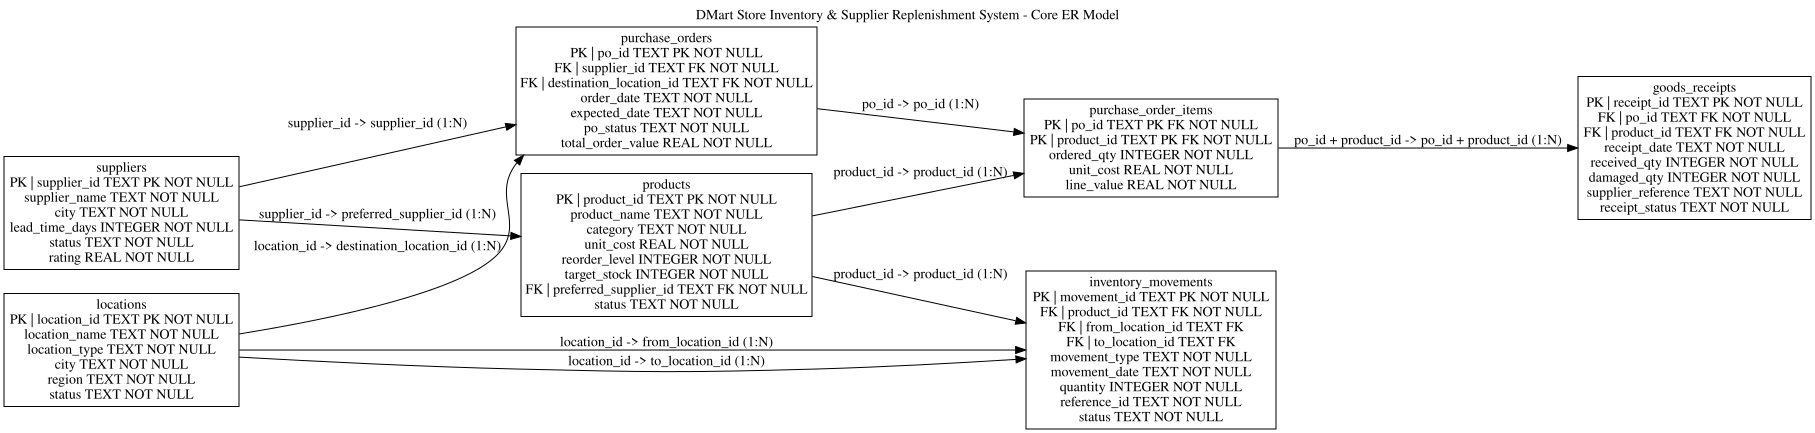

ER-1: Passed - complete normalized ER definition validated.


True

In [ ]:
# SQL DEVELOPER WORKSPACE
developer_tables={
    "suppliers": [
        "supplier_id TEXT PK NOT NULL",
        "supplier_name TEXT NOT NULL",
        "city TEXT NOT NULL",
        "lead_time_days INTEGER NOT NULL",
        "status TEXT NOT NULL",
        "rating REAL NOT NULL",
    ],
    "locations": [
        "location_id TEXT PK NOT NULL",
        "location_name TEXT NOT NULL",
        "location_type TEXT NOT NULL",
        "city TEXT NOT NULL",
        "region TEXT NOT NULL",
        "status TEXT NOT NULL",
    ],
    "products": [
        "product_id TEXT PK NOT NULL",
        "product_name TEXT NOT NULL",
        "category TEXT NOT NULL",
        "unit_cost REAL NOT NULL",
        "reorder_level INTEGER NOT NULL",
        "target_stock INTEGER NOT NULL",
        "preferred_supplier_id TEXT FK NOT NULL",
        "status TEXT NOT NULL",
    ],
    "purchase_orders": [
        "po_id TEXT PK NOT NULL",
        "supplier_id TEXT FK NOT NULL",
        "destination_location_id TEXT FK NOT NULL",
        "order_date TEXT NOT NULL",
        "expected_date TEXT NOT NULL",
        "po_status TEXT NOT NULL",
        "total_order_value REAL NOT NULL",
    ],
    "purchase_order_items": [
        "po_id TEXT PK FK NOT NULL",
        "product_id TEXT PK FK NOT NULL",
        "ordered_qty INTEGER NOT NULL",
        "unit_cost REAL NOT NULL",
        "line_value REAL NOT NULL",
    ],
    "goods_receipts": [
        "receipt_id TEXT PK NOT NULL",
        "po_id TEXT FK NOT NULL",
        "product_id TEXT FK NOT NULL",
        "receipt_date TEXT NOT NULL",
        "received_qty INTEGER NOT NULL",
        "damaged_qty INTEGER NOT NULL",
        "supplier_reference TEXT NOT NULL",
        "receipt_status TEXT NOT NULL",
    ],
    "inventory_movements": [
        "movement_id TEXT PK NOT NULL",
        "product_id TEXT FK NOT NULL",
        "from_location_id TEXT FK",
        "to_location_id TEXT FK",
        "movement_type TEXT NOT NULL",
        "movement_date TEXT NOT NULL",
        "quantity INTEGER NOT NULL",
        "reference_id TEXT NOT NULL",
        "status TEXT NOT NULL",
    ],


}
developer_relationships=[
    (
        "suppliers", "supplier_id",
        "products", "preferred_supplier_id", "1:N"
    ),
    (
        "suppliers", "supplier_id",
        "purchase_orders", "supplier_id", "1:N"
    ),
    (
        "locations", "location_id",
        "purchase_orders", "destination_location_id", "1:N"
    ),
    (
        "purchase_orders", "po_id",
        "purchase_order_items", "po_id", "1:N"
    ),
    (
        "products", "product_id",
        "purchase_order_items", "product_id", "1:N"
    ),
    (
        "purchase_order_items", "po_id + product_id",
        "goods_receipts", "po_id + product_id", "1:N"
    ),
    (
        "products", "product_id",
        "inventory_movements", "product_id", "1:N"
    ),
    (
        "locations", "location_id",
        "inventory_movements", "from_location_id", "1:N"
    ),
    (
        "locations", "location_id",
        "inventory_movements", "to_location_id", "1:N"
    ),

]
# TODO: Define exactly seven core tables, required PK/FK markers, the composite key, and every required relationship beneath this guidance.
validate_er(developer_tables,developer_relationships)

### Expected Output
- Seven connected core table boxes.
- Primary-key and foreign-key markers present.
- Composite primary key in `purchase_order_items`.
- All required relationships validated.
- A visible ER diagram generated automatically.
- Overall status: `Passed`.

# 3. API Operations
Complete five independent internal API activities. Every mutable practice record is reset before the request so each activity remains rerunnable.

In [ ]:
display(endpoint_docs)
print('Use BASE_URL:',BASE_URL)

,Method,Endpoint,Purpose,Expected Status
0,GET,/products,Read product master data,200
1,GET,/locations,Read store and warehouse master data,200
2,GET,/suppliers,Read supplier master data,200
3,GET,/purchase_orders,Read purchase-order headers,200
4,GET,/purchase_order_items,Read purchase-order line items,200
5,GET,/goods_receipts,Read goods-receipt records,200
6,GET,/inventory_movements,Read movement records with filters,200
7,GET,/inventory_movements/{id},Read one inventory movement,200 / 404
8,POST,/inventory_movements,Create one inventory movement,201 / 400 / 409
9,PUT,/inventory_movements/{id},Completely replace one movement,200 / 400 / 404


Use BASE_URL: http://127.0.0.1:39717


## API-Q1 - Filtered GET
**Business requirement - Inventory Operations Lead:** Fetch exactly five posted sales movements for a small API quality check.

**Provided endpoint:** `GET /inventory_movements`

**How to approach:** send query parameters `limit=5`, `movement_type=SALE`, and `status=POSTED`; use a timeout.

In [ ]:
# SQL DEVELOPER WORKSPACE
api_q1_response=requests.get(BASE_URL + "/inventory_movements",
                             params={
                                 "limit":5,
                                 "movement_type":"SALE",
                                 "status":"POSTED"
                             },
                             timeout=10
                             )
if api_q1_response is None:
    record_status("API-Q1",False,"Filtered GET request is unanswered.")
else:
    try:
        payload=api_q1_response.json()
        display(pd.DataFrame(payload))
        ok=(api_q1_response.status_code==200 and len(payload)==5 and
            all(r.get("movement_type")=="SALE" and r.get("status")=="POSTED" for r in payload))
        record_status("API-Q1",ok,f"HTTP {api_q1_response.status_code}; records={len(payload)}.")
    except Exception as exc:
        record_status("API-Q1",False,f"GET validation failed safely: {exc}")

,movement_id,product_id,from_location_id,to_location_id,movement_type,movement_date,quantity,reference_id,status
0,MOV0004054,P0014,LOC008,None,SALE,2026-07-01 05:37:00,8,SALE-000001,POSTED
1,MOV0004055,P0027,LOC001,None,SALE,2026-07-01 11:14:00,2,SALE-000002,POSTED
2,MOV0004056,P0040,LOC008,None,SALE,2026-07-01 16:51:00,8,SALE-000003,POSTED
3,MOV0004057,P0053,LOC001,None,SALE,2026-07-01 22:28:00,2,SALE-000004,POSTED
4,MOV0004058,P0066,LOC008,None,SALE,2026-07-02 04:05:00,8,SALE-000005,POSTED


API-Q1: Passed - HTTP 200; records=5.


### Expected Output
| Check | Expected |
|---|---|
| HTTP status | `200` |
| Record count | `5` |
| `movement_type` for every record | `SALE` |
| `status` for every record | `POSTED` |

**Hint:** Use `requests.get(..., params=..., timeout=10)`.

## API-Q2 - POST a customer return movement
**Business requirement - Store Inventory Control Manager:** Record the provided posted customer-return movement through the internal API.

The complete `post_payload` and target URL are already prepared in the workspace.

In [ ]:
# SQL DEVELOPER WORKSPACE
post_id="API-MOV-POST-001"
remove_api_record(post_id)
post_payload={
 "movement_id":post_id,"product_id":"P0001","from_location_id":None,"to_location_id":"LOC001",
 "movement_type":"CUSTOMER_RETURN","movement_date":"2026-07-31 15:30:00","quantity":3,
 "reference_id":"RET-API-001","status":"POSTED"
}
api_q2_response=requests.post(BASE_URL + "/inventory_movements", json=post_payload, timeout=10)
if api_q2_response is None:
    record_status("API-Q2",False,"POST request is unanswered.")
else:
    try:
        payload=api_q2_response.json()
        display(pd.DataFrame([payload]))
        ok=(api_q2_response.status_code==201 and payload==post_payload)
        record_status("API-Q2",ok,f"HTTP {api_q2_response.status_code}; created ID={payload.get('movement_id')}.")
    except Exception as exc:
        record_status("API-Q2",False,f"POST validation failed safely: {exc}")

,movement_id,product_id,from_location_id,to_location_id,movement_type,movement_date,quantity,reference_id,status
0,API-MOV-POST-001,P0001,None,LOC001,CUSTOMER_RETURN,2026-07-31 15:30:00,3,RET-API-001,POSTED


API-Q2: Passed - HTTP 201; created ID=API-MOV-POST-001.


### Expected Output
| Check | Expected |
|---|---|
| HTTP status | `201` |
| Created movement ID | `API-MOV-POST-001` |
| Returned fields | Exact `post_payload` values |

**Hint:** Use `requests.post(..., json=post_payload, timeout=10)`.

## API-Q3 - PUT complete transfer replacement
**Business requirement - Warehouse Operations Lead:** Completely replace the reset transfer practice record with the provided approved replacement content.

The complete `put_payload` and record ID are already prepared.

In [ ]:
# SQL DEVELOPER WORKSPACE
put_id="API-MOV-PUT-001"
reset_api_record(put_id)
put_payload={
 "movement_id":put_id,"product_id":"P0010","from_location_id":"LOC018","to_location_id":"LOC004",
 "movement_type":"TRANSFER","movement_date":"2026-07-31 16:00:00","quantity":22,
 "reference_id":"TRF-API-PUT-REPLACED","status":"POSTED"
}
api_q3_response=requests.put(BASE_URL + f"/inventory_movements/{put_id}", json=put_payload, timeout=10)
if api_q3_response is None:
    record_status("API-Q3",False,"PUT request is unanswered.")
else:
    try:
        payload=api_q3_response.json()
        display(pd.DataFrame([payload]))
        ok=(api_q3_response.status_code==200 and payload==put_payload and set(payload)==set(API_MOVEMENT_FIELDS))
        record_status("API-Q3",ok,f"HTTP {api_q3_response.status_code}; complete replacement validated.")
    except Exception as exc:
        record_status("API-Q3",False,f"PUT validation failed safely: {exc}")

,movement_id,product_id,from_location_id,to_location_id,movement_type,movement_date,quantity,reference_id,status
0,API-MOV-PUT-001,P0010,LOC018,LOC004,TRANSFER,2026-07-31 16:00:00,22,TRF-API-PUT-REPLACED,POSTED


API-Q3: Passed - HTTP 200; complete replacement validated.


### Expected Output
| Check | Expected |
|---|---|
| HTTP status | `200` |
| Movement ID | `API-MOV-PUT-001` |
| Replacement behavior | Every field equals `put_payload`; no baseline values remain |

**Hint:** Use `requests.put(..., json=put_payload, timeout=10)`.

## API-Q4 - PATCH selected damage fields
**Business requirement - Inventory Risk Lead:** Update only the quantity and status of a reset damage movement while preserving all untargeted fields.

The workspace captures the baseline response before the update.

In [ ]:
# SQL DEVELOPER WORKSPACE
patch_id="API-MOV-PATCH-001"
baseline=reset_api_record(patch_id)
before=requests.get(BASE_URL+f"/inventory_movements/{patch_id}",timeout=10).json()
patch_payload={"quantity":6,"status":"POSTED"}
api_q4_response=requests.patch(BASE_URL + f"/inventory_movements/{patch_id}", json=patch_payload, timeout=10)
if api_q4_response is None:
    record_status("API-Q4",False,"PATCH request is unanswered.")
else:
    try:
        after=api_q4_response.json()
        display(pd.DataFrame([before,after],index=["Before","After"]))
        untouched=[k for k in API_MOVEMENT_FIELDS if k not in patch_payload]
        ok=(api_q4_response.status_code==200 and all(after.get(k)==v for k,v in patch_payload.items()) and
            all(after.get(k)==before.get(k) for k in untouched))
        record_status("API-Q4",ok,f"HTTP {api_q4_response.status_code}; targeted fields changed and untargeted fields preserved.")
    except Exception as exc:
        record_status("API-Q4",False,f"PATCH validation failed safely: {exc}")

,movement_id,product_id,from_location_id,to_location_id,movement_type,movement_date,quantity,reference_id,status
Before,API-MOV-PATCH-001,P0003,LOC002,None,DAMAGE,2026-07-31 14:15:00,4,DMG-API-PATCH-BASE,PENDING
After,API-MOV-PATCH-001,P0003,LOC002,None,DAMAGE,2026-07-31 14:15:00,6,DMG-API-PATCH-BASE,POSTED


API-Q4: Passed - HTTP 200; targeted fields changed and untargeted fields preserved.


### Expected Output
| Check | Expected |
|---|---|
| HTTP status | `200` |
| Updated `quantity` | `6` |
| Updated `status` | `POSTED` |
| Untargeted fields | Unchanged from baseline |

**Hint:** Use `requests.patch(..., json=patch_payload, timeout=10)`.

## API-Q5 - GET -> DELETE -> GET verification
**Business requirement - Engineering Manager:** Prove deletion semantics on a reset transfer practice record.

Read the record, delete it, and read it again.

In [ ]:
# SQL DEVELOPER WORKSPACE
delete_id="API-MOV-DELETE-001"
reset_api_record(delete_id)
api_q5_first=requests.get(BASE_URL+f"/inventory_movements/{delete_id}",timeout=10)
api_q5_delete=requests.delete(BASE_URL+f"/inventory_movements/{delete_id}",timeout=10)
api_q5_after=requests.get(BASE_URL+f"/inventory_movements/{delete_id}",timeout=10)
if None in (api_q5_first,api_q5_delete,api_q5_after):
    record_status("API-Q5",False,"GET -> DELETE -> GET sequence is unanswered.")
else:
    codes=[api_q5_first.status_code,api_q5_delete.status_code,api_q5_after.status_code]
    display(pd.DataFrame([["GET before",codes[0]],["DELETE",codes[1]],["GET after",codes[2]]],columns=["Request","HTTP status"]))
    record_status("API-Q5",codes==[200,200,404],f"Status sequence={codes}.")

,Request,HTTP status
0,GET before,200
1,DELETE,200
2,GET after,404


API-Q5: Passed - Status sequence=[200, 200, 404].


### Expected Output
| Request | Expected HTTP status |
|---|---|
| GET before delete | `200` |
| DELETE | `200` |
| GET after delete | `404` |

**Hint:** Use `requests.get`, `requests.delete`, then `requests.get`, all with `timeout=10`.

# 4. SQL Developer Questions
Use SQLite SQL for every business requirement. Python and Pandas are used only to display and validate the SQL result.

In [ ]:
schema_overview=pd.DataFrame(conn.execute(
    "SELECT name,type FROM sqlite_master WHERE type IN ('table','index') AND name NOT LIKE 'sqlite_%' ORDER BY type,name"
).fetchall(),columns=["Object","Type"])
display(schema_overview)
print("Core and system-managed database objects are ready for SQL work.")

,Object,Type
0,idx_exceptions_product_location,index
1,idx_exceptions_type_status,index
2,idx_movements_from_status,index
3,idx_movements_product_date,index
4,idx_movements_to_status,index
5,idx_movements_type_status,index
6,idx_po_destination_status,index
7,idx_po_supplier_date,index
8,idx_poi_product,index
9,idx_products_supplier,index


Core and system-managed database objects are ready for SQL work.


## 4A. Foundations and Operational SQL
Filtering, sorting, aggregation, HAVING, joins, reconciliation, and missing-record analysis.

## Q1 - Largest posted store sales movements
**Business requirement - Inventory Operations Lead:** List the ten largest posted SALE movements so operations can inspect unusually high unit movements before daily stock balancing.

**Tables to use:** inventory_movements, products, locations

**How to approach**
1. Join movements to product and source-location master data; filter to posted SALE rows; sort by quantity descending and use deterministic tie-breakers; return ten rows.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE

q1_query = """
SELECT
    im.movement_id,
    im.product_id,
    p.product_name,
    l.location_name,
    im.quantity,
    im.movement_date
FROM inventory_movements AS im
INNER JOIN products AS p
    ON im.product_id = p.product_id
INNER JOIN locations AS l
    ON im.from_location_id = l.location_id
WHERE im.movement_type = 'SALE'
  AND im.status = 'POSTED'
ORDER BY
    im.quantity DESC,
    im.movement_date ASC,
    im.movement_id ASC
LIMIT 10;
"""

validate_sql("Q1", q1_query)


,movement_id,product_id,product_name,location_name,quantity,movement_date
0,MOV0005378,P0118,Smart Namkeen 118,DMart Nagpur Store 1,12,2026-07-01 02:05:00
1,MOV0004186,P0090,Premium Juice 090,DMart Nagpur Store 1,12,2026-07-01 03:01:00
2,MOV0006703,P0117,Essential Milk 117,DMart Mumbai Store 1,12,2026-07-01 04:10:00
3,MOV0005511,P0089,Pure Cereal 089,DMart Mumbai Store 1,12,2026-07-01 05:06:00
4,MOV0004319,P0061,Classic Curd 061,DMart Mumbai Store 1,12,2026-07-01 06:02:00
5,MOV0005644,P0060,Premium Floor Cleaner 060,DMart Nagpur Store 1,12,2026-07-01 08:07:00
6,MOV0004452,P0032,Fresh Cooking Oil 032,DMart Nagpur Store 1,12,2026-07-01 09:03:00
7,MOV0005777,P0031,Classic Shampoo 031,DMart Mumbai Store 1,12,2026-07-01 11:08:00
8,MOV0004585,P0003,Everyday Detergent 003,DMart Mumbai Store 1,12,2026-07-01 12:04:00
9,MOV0005910,P0002,Fresh Coffee 002,DMart Nagpur Store 1,12,2026-07-01 14:09:00


,Validation,Passed,Actual
0,Exact columns,True,"['movement_id', 'product_id', 'product_name', ..."
1,Expected row count,True,10
2,Stable first row / key result,True,"{'movement_id': 'MOV0005378', 'product_id': 'P..."


Q1: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `movement_id`, `product_id`, `product_name`, `location_name`, `quantity`, `movement_date`
- **Expected row count:** **10**
- **Stable first row / key result:** `movement_id` = `MOV0005378`, `product_id` = `P0118`, `product_name` = `Smart Namkeen 118`, `location_name` = `DMart Nagpur Store 1`, `quantity` = `12`, `movement_date` = `2026-07-01 02:05:00`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use INNER JOIN, WHERE, ORDER BY, and LIMIT.


## Q2 - High-demand product totals
**Business requirement - Category Planning Manager:** Identify products whose July posted sales reached at least 145 units, with event counts and inventory-cost value, to prioritize replenishment attention.

**Tables to use:** inventory_movements, products

**How to approach**
1. Filter posted SALE movements; group by product; calculate COUNT, SUM(quantity), and SUM(quantity * unit_cost); keep groups meeting the threshold.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE

q2_query = """
SELECT
    p.product_id,
    p.product_name,
    p.category,
    COUNT(im.movement_id) AS sale_events,
    SUM(im.quantity) AS units_sold,
    SUM(im.quantity * p.unit_cost) AS inventory_cost_value
FROM inventory_movements AS im
INNER JOIN products AS p
    ON im.product_id = p.product_id
WHERE im.movement_type = 'SALE'
  AND im.status = 'POSTED'
  AND im.movement_date >= '2026-07-01'
  AND im.movement_date < '2026-08-01'
GROUP BY
    p.product_id,
    p.product_name,
    p.category
HAVING SUM(im.quantity) >= 145
ORDER BY
    units_sold DESC,
    p.product_id ASC;
"""

validate_sql("Q2", q2_query)


,product_id,product_name,category,sale_events,units_sold,inventory_cost_value
0,P0007,Essential Shampoo 007,Personal Care,30,201,55677.00
1,P0101,Classic Paneer 101,Dairy,30,201,63526.05
2,P0111,Classic Soap 111,Personal Care,30,201,51677.10
3,P0091,Classic Tissues 091,Household,29,198,74250.00
4,P0035,Value Garbage Bags 035,Household,28,196,4508.00
...,...,...,...,...,...,...
82,P0093,Everyday Milk 093,Dairy,23,148,2915.60
83,P0067,Essential Tissues 067,Household,22,147,51214.80
84,P0066,Select Juice 066,Beverages,21,146,45413.30
85,P0062,Fresh Snack Mix 062,Snacks,23,145,23794.50


,Validation,Passed,Actual
0,Exact columns,True,"['product_id', 'product_name', 'category', 'sa..."
1,Expected row count,True,87
2,Stable first row / key result,True,"{'product_id': 'P0007', 'product_name': 'Essen..."


Q2: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `product_id`, `product_name`, `category`, `sale_events`, `units_sold`, `inventory_cost_value`
- **Expected row count:** **87**
- **Stable first row / key result:** `product_id` = `P0007`, `product_name` = `Essential Shampoo 007`, `category` = `Personal Care`, `sale_events` = `30`, `units_sold` = `201`, `inventory_cost_value` = `55677.0`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use GROUP BY, SUM, COUNT, HAVING, and deterministic ordering.


## Q3 - Purchase-order quantity reconciliation
**Business requirement - Procurement Control Lead:** Show the twenty largest purchase-order line mismatches between ordered and received quantity, classified as SHORT or OVER, for supplier follow-up.

**Tables to use:** purchase_orders, purchase_order_items, products, goods_receipts

**How to approach**
1. Join order headers and lines to products; LEFT JOIN receipts by both po_id and product_id; aggregate received quantity; compare it with ordered quantity using COALESCE and CASE.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE

q3_query = """
WITH receipt_totals AS (
    SELECT
        po_id,
        product_id,
        SUM(received_qty) AS received_qty
    FROM goods_receipts
    WHERE receipt_date < '2026-08-02 00:00:00'
    GROUP BY
        po_id,
        product_id
),
order_reconciliation AS (
    SELECT
        po.po_id,
        poi.product_id,
        p.product_name,
        poi.ordered_qty,
        COALESCE(rt.received_qty, 0) AS received_qty,
        COALESCE(rt.received_qty, 0) - poi.ordered_qty
            AS quantity_variance
    FROM purchase_orders AS po
    INNER JOIN purchase_order_items AS poi
        ON po.po_id = poi.po_id
    INNER JOIN products AS p
        ON poi.product_id = p.product_id
    LEFT JOIN receipt_totals AS rt
        ON poi.po_id = rt.po_id
       AND poi.product_id = rt.product_id
)
SELECT
    po_id,
    product_id,
    product_name,
    ordered_qty,
    received_qty,
    quantity_variance,
    CASE
        WHEN quantity_variance < 0 THEN 'SHORT'
        WHEN quantity_variance > 0 THEN 'OVER'
    END AS receipt_classification
FROM order_reconciliation
WHERE quantity_variance <> 0
ORDER BY
    ABS(quantity_variance) DESC,
    po_id ASC,
    product_id ASC
LIMIT 20;
"""

validate_sql("Q3", q3_query)


,po_id,product_id,product_name,ordered_qty,received_qty,quantity_variance,receipt_classification
0,PO00297,P0022,Fresh Namkeen 022,139,0,-139,SHORT
1,PO00148,P0073,Everyday Noodles 073,135,0,-135,SHORT
2,PO00111,P0111,Classic Soap 111,134,0,-134,SHORT
3,PO00248,P0023,Everyday Toothpaste 023,133,0,-133,SHORT
4,PO00065,P0065,Value Cereal 065,132,0,-132,SHORT
5,PO00016,P0066,Select Juice 066,126,0,-126,SHORT
6,PO00074,P0024,Family Rice 024,126,0,-126,SHORT
7,PO00037,P0062,Fresh Snack Mix 062,125,0,-125,SHORT
8,PO00271,P0096,Select Rice 096,125,0,-125,SHORT
9,PO00074,P0021,Classic Milk 021,123,0,-123,SHORT


,Validation,Passed,Actual
0,Exact columns,True,"['po_id', 'product_id', 'product_name', 'order..."
1,Expected row count,True,20
2,Stable first row / key result,True,"{'po_id': 'PO00297', 'product_id': 'P0022', 'p..."


Q3: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `po_id`, `product_id`, `product_name`, `ordered_qty`, `received_qty`, `quantity_variance`, `receipt_classification`
- **Expected row count:** **20**
- **Stable first row / key result:** `po_id` = `PO00297`, `product_id` = `P0022`, `product_name` = `Fresh Namkeen 022`, `ordered_qty` = `139`, `received_qty` = `0`, `quantity_variance` = `-139`, `receipt_classification` = `SHORT`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use a duplicate-safe LEFT JOIN, an as-of receipt-date condition, SUM, COALESCE, CASE, HAVING, and ABS.


## Q4 - Purchase-order lines with no receipt
**Business requirement - Replenishment Operations Manager:** Find non-cancelled purchase-order lines due by the review date that have no matching goods-receipt record.

**Tables to use:** purchase_orders, purchase_order_items, products, suppliers, goods_receipts

**How to approach**
1. Join order, product, and supplier context; LEFT JOIN receipts on the full business key; filter where the receipt primary key is NULL.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE
q4_query = """
SELECT
    po.po_id,
    poi.product_id,
    p.product_name,
    s.supplier_name,
    po.expected_date,
    poi.ordered_qty
FROM purchase_orders AS po
INNER JOIN purchase_order_items AS poi
    ON po.po_id = poi.po_id
INNER JOIN products AS p
    ON poi.product_id = p.product_id
INNER JOIN suppliers AS s
    ON po.supplier_id = s.supplier_id
LEFT JOIN goods_receipts AS gr
    ON poi.po_id = gr.po_id
   AND poi.product_id = gr.product_id
   AND gr.receipt_date < '2026-08-01 00:00:00'
WHERE po.po_status <> 'CANCELLED'
  AND po.expected_date <= '2026-08-01'
  AND gr.receipt_id IS NULL
ORDER BY
    po.expected_date ASC,
    po.po_id ASC,
    poi.product_id ASC;
"""

validate_sql("Q4", q4_query)

,po_id,product_id,product_name,supplier_name,expected_date,ordered_qty
0,PO00135,P0089,Pure Cereal 089,Lotus Foods 21,2026-07-02,48
1,PO00033,P0033,Everyday Biscuits 033,Indus Foods 07,2026-07-05,28
2,PO00162,P0037,Essential Curd 037,Evergreen Consumer 10,2026-07-05,101
3,PO00335,P0010,Premium Tea 010,Lotus Foods 21,2026-07-05,65
4,PO00103,P0028,Smart Dishwash 028,Bharat Products 22,2026-07-06,33
...,...,...,...,...,...,...
68,PO00286,P0011,Classic Garbage Bags 011,Jupiter Consumer 03,2026-08-01,59
69,PO00286,P0061,Classic Curd 061,Jupiter Consumer 03,2026-08-01,109
70,PO00291,P0041,Classic Cereal 041,Aarav Supplies 13,2026-08-01,56
71,PO00291,P0116,Select Surface Cleaner 116,Aarav Supplies 13,2026-08-01,131


,Validation,Passed,Actual
0,Exact columns,True,"['po_id', 'product_id', 'product_name', 'suppl..."
1,Expected row count,True,73
2,Stable first row / key result,True,"{'po_id': 'PO00135', 'product_id': 'P0089', 'p..."


Q4: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `po_id`, `product_id`, `product_name`, `supplier_name`, `expected_date`, `ordered_qty`
- **Expected row count:** **73**
- **Stable first row / key result:** `po_id` = `PO00135`, `product_id` = `P0089`, `product_name` = `Pure Cereal 089`, `supplier_name` = `Lotus Foods 21`, `expected_date` = `2026-07-02`, `ordered_qty` = `48`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use LEFT JOIN with the review-date condition in the join and an IS NULL anti-join condition.


## 4B. Functions, Set Operations, Subqueries, and Standard CTEs
Use SQL functions and non-recursive CTEs for operational controls and replenishment logic.

## Q5 - Returned products with open inventory risk
**Business requirement - Store Inventory Control Manager:** Return the products that appear in posted customer returns and also have an open DAMAGE_SPIKE or LOW_STOCK_REORDER exception.

**Tables to use:** inventory_movements, inventory_exceptions, products

**How to approach**
1. Build the two product-id sets, intersect them, then join the final set to product master data.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE

q5_query = """
WITH returned_products AS (
    SELECT DISTINCT product_id
    FROM inventory_movements
    WHERE movement_type = 'CUSTOMER_RETURN'
      AND status = 'POSTED'
),
open_risk_products AS (
    SELECT DISTINCT product_id
    FROM inventory_exceptions
    WHERE exception_type IN ('DAMAGE_SPIKE', 'LOW_STOCK_REORDER')
      AND resolution_status = 'OPEN'
),
qualifying_products AS (
    SELECT product_id
    FROM returned_products
    INTERSECT
    SELECT product_id
    FROM open_risk_products
)
SELECT
    p.product_id,
    p.product_name,
    p.category
FROM qualifying_products AS qp
INNER JOIN products AS p
    ON qp.product_id = p.product_id
ORDER BY p.product_id ASC;
"""

validate_sql("Q5", q5_query)

,product_id,product_name,category
0,P0001,Classic Noodles 001,Packaged Food
1,P0003,Everyday Detergent 003,Household
2,P0004,Family Dishwash 004,Home Care
3,P0006,Select Chips 006,Snacks
4,P0007,Essential Shampoo 007,Personal Care
...,...,...,...
88,P0111,Classic Soap 111,Personal Care
89,P0112,Fresh Flour 112,Staples
90,P0113,Everyday Cereal 113,Packaged Food
91,P0116,Select Surface Cleaner 116,Home Care


,Validation,Passed,Actual
0,Exact columns,True,"['product_id', 'product_name', 'category']"
1,Expected row count,True,93
2,Stable first row / key result,True,"{'product_id': 'P0001', 'product_name': 'Class..."


Q5: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `product_id`, `product_name`, `category`
- **Expected row count:** **93**
- **Stable first row / key result:** `product_id` = `P0001`, `product_name` = `Classic Noodles 001`, `category` = `Packaged Food`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use INTERSECT (or an equivalent set operation) and a final join.


## Q6 - Supplier risk report
**Business requirement - Supplier Performance Manager:** Create a supplier report with uppercase names, a short supplier code, average receipt delay against the promised date, supplier-specific open exception count, and a readable risk band.

**Tables to use:** suppliers, purchase_orders, purchase_order_items, goods_receipts, inventory_exceptions

**How to approach**
1. Use standard CTEs to calculate the first accepted/partial receipt per purchase-order line as of 1 August 2026 and supplier-specific exception counts.
2. Measure delay from the purchase order's `expected_date`, treating unreceived due lines as delayed through the review date; do not count stock, damage, or transfer exceptions as supplier-performance failures.
3. Keep the result deterministic using the ordering stated in the requirement.
4. Return only the columns requested in the expected output.


In [ ]:
# SQL DEVELOPER WORKSPACE

q6_query = """
WITH line_receipts AS (
    SELECT
        po.po_id,
        po.supplier_id,
        poi.product_id,
        po.expected_date,
        MIN(
            CASE
                WHEN gr.receipt_status IN ('ACCEPTED', 'PARTIAL')
                 AND gr.receipt_date < '2026-08-02 00:00:00'
                THEN gr.receipt_date
            END
        ) AS first_receipt_date
    FROM purchase_orders AS po
    INNER JOIN purchase_order_items AS poi
        ON po.po_id = poi.po_id
    LEFT JOIN goods_receipts AS gr
        ON poi.po_id = gr.po_id
       AND poi.product_id = gr.product_id
    WHERE po.po_status <> 'CANCELLED'
      AND po.expected_date <= '2026-08-01'
    GROUP BY
        po.po_id,
        po.supplier_id,
        poi.product_id,
        po.expected_date
),
supplier_delays AS (
    SELECT
        supplier_id,
        CASE
            WHEN first_receipt_date IS NOT NULL THEN
                MAX(
                    0,
                    CAST(
                        julianday(first_receipt_date)
                        - julianday(expected_date) AS INTEGER
                    )
                )
            ELSE
                MAX(
                    0,
                    CAST(
                        julianday('2026-08-01')
                        - julianday(expected_date) AS INTEGER
                    )
                )
        END AS delay_days
    FROM line_receipts
),
supplier_delay_summary AS (
    SELECT
        supplier_id,
        ROUND(AVG(delay_days), 1) AS avg_receipt_delay_days
    FROM supplier_delays
    GROUP BY supplier_id
),
supplier_exception_summary AS (
    SELECT
        supplier_id,
        COUNT(*) AS open_exceptions
    FROM inventory_exceptions
    WHERE resolution_status = 'OPEN'
      AND supplier_id IS NOT NULL
      AND exception_type IN (
          'MISSING_RECEIPT',
          'SHORT_RECEIPT',
          'OVER_RECEIPT',
          'LATE_RECEIPT',
          'DUPLICATE_SUPPLIER_REFERENCE'
      )
    GROUP BY supplier_id
)
SELECT
    s.supplier_id,
    UPPER(s.supplier_name) AS supplier_name_upper,
    SUBSTR(s.supplier_id, 4) AS supplier_code,
    COALESCE(ds.avg_receipt_delay_days, 0.0)
        AS avg_receipt_delay_days,
    COALESCE(es.open_exceptions, 0) AS open_exceptions,
    CASE
        WHEN COALESCE(es.open_exceptions, 0) >= 15
          OR COALESCE(ds.avg_receipt_delay_days, 0) >= 5
            THEN 'HIGH'
        WHEN COALESCE(es.open_exceptions, 0) >= 8
          OR COALESCE(ds.avg_receipt_delay_days, 0) >= 2
            THEN 'MEDIUM'
        ELSE 'LOW'
    END AS supplier_risk_band
FROM suppliers AS s
LEFT JOIN supplier_delay_summary AS ds
    ON s.supplier_id = ds.supplier_id
LEFT JOIN supplier_exception_summary AS es
    ON s.supplier_id = es.supplier_id
ORDER BY
    open_exceptions DESC,
    s.supplier_id ASC;
"""

validate_sql("Q6", q6_query)


,supplier_id,supplier_name_upper,supplier_code,avg_receipt_delay_days,open_exceptions,supplier_risk_band
0,SUP008,LOTUS PRODUCTS 08,008,0.8,17,HIGH
1,SUP013,AARAV SUPPLIES 13,013,0.7,15,HIGH
2,SUP006,FRESHWAY SUPPLIES 06,006,1.3,13,MEDIUM
3,SUP020,INDUS SUPPLIES 20,020,0.9,13,MEDIUM
4,SUP022,BHARAT PRODUCTS 22,022,1.7,13,MEDIUM
5,SUP014,DELTA FOODS 14,014,0.8,12,MEDIUM
6,SUP017,METRO CONSUMER 17,017,0.9,12,MEDIUM
7,SUP021,LOTUS FOODS 21,021,2.0,12,MEDIUM
8,SUP025,KAVERI WHOLESALE 25,025,1.0,12,MEDIUM
9,SUP003,JUPITER CONSUMER 03,003,0.4,11,MEDIUM


,Validation,Passed,Actual
0,Exact columns,True,"['supplier_id', 'supplier_name_upper', 'suppli..."
1,Expected row count,True,25
2,Stable first row / key result,True,"{'supplier_id': 'SUP008', 'supplier_name_upper..."


Q6: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `supplier_id`, `supplier_name_upper`, `supplier_code`, `avg_receipt_delay_days`, `open_exceptions`, `supplier_risk_band`
- **Expected row count:** **25**
- **Stable first row / key result:** `supplier_id` = `SUP008`, `supplier_name_upper` = `LOTUS PRODUCTS 08`, `supplier_code` = `008`, `avg_receipt_delay_days` = `0.8`, `open_exceptions` = `17`, `supplier_risk_band` = `HIGH`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use UPPER, SUBSTR, julianday, COALESCE, ROUND, CASE, line-level receipt aggregation, and standard CTEs.


## Q7 - Products selling above the portfolio average
**Business requirement - Merchandising Analytics Lead:** Identify products whose total posted sale units are above the average product sales total for the review period.

**Tables to use:** products, inventory_movements

**How to approach**
1. Aggregate sales by product in a CTE or derived table, then compare each total with a scalar subquery calculating the average.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE

q7_query = """
WITH product_sales AS (
    SELECT
        p.product_id,
        p.product_name,
        p.category,
        SUM(im.quantity) AS units_sold
    FROM products AS p
    JOIN inventory_movements AS im
        ON p.product_id = im.product_id
    WHERE im.movement_type = 'SALE'
      AND im.status = 'POSTED'
      AND im.movement_date >= '2026-07-01'
      AND im.movement_date < '2026-08-01'
    GROUP BY
        p.product_id,
        p.product_name,
        p.category
)
SELECT
    product_id,
    product_name,
    category,
    units_sold
FROM product_sales
WHERE units_sold > (
    SELECT AVG(units_sold)
    FROM product_sales
)
ORDER BY
    units_sold DESC,
    product_id ASC;
"""

validate_sql("Q7", q7_query)

,product_id,product_name,category,units_sold
0,P0007,Essential Shampoo 007,Personal Care,201
1,P0101,Classic Paneer 101,Dairy,201
2,P0111,Classic Soap 111,Personal Care,201
3,P0091,Classic Tissues 091,Household,198
4,P0035,Value Garbage Bags 035,Household,196
5,P0013,Everyday Curd 013,Dairy,195
6,P0023,Everyday Toothpaste 023,Personal Care,195
7,P0033,Everyday Biscuits 033,Packaged Food,195
8,P0037,Essential Curd 037,Dairy,195
9,P0051,Classic Detergent 051,Household,195


,Validation,Passed,Actual
0,Exact columns,True,"['product_id', 'product_name', 'category', 'un..."
1,Expected row count,True,56
2,Stable first row / key result,True,"{'product_id': 'P0007', 'product_name': 'Essen..."


Q7: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `product_id`, `product_name`, `category`, `units_sold`
- **Expected row count:** **56**
- **Stable first row / key result:** `product_id` = `P0007`, `product_name` = `Essential Shampoo 007`, `category` = `Personal Care`, `units_sold` = `201`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use a standard CTE (or derived table) plus a scalar subquery.


## Q8 - Daily replenishment recommendations
**Business requirement - Replenishment Planning Lead:** Produce the top 25 store-product replenishment recommendations as of 1 August 2026 using current stock, reorder level, target stock, the most recent seven days of posted sales, and preferred-supplier operating status.

**Tables to use:** products, locations, suppliers, inventory_movements

**How to approach**
1. Create movement effects, current-stock, recent-sales, and reorder-pool CTEs; calculate recommended quantity for active store products below reorder level; join preferred supplier and expose whether the recommendation is order-ready or requires supplier review.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE

q8_query = """
WITH movement_effects AS (
    SELECT
        product_id,
        to_location_id AS location_id,
        quantity AS stock_change,
        movement_date
    FROM inventory_movements
    WHERE status = 'POSTED'
      AND to_location_id IS NOT NULL

    UNION ALL

    SELECT
        product_id,
        from_location_id AS location_id,
        -quantity AS stock_change,
        movement_date
    FROM inventory_movements
    WHERE status = 'POSTED'
      AND from_location_id IS NOT NULL
),
current_stock AS (
    SELECT
        product_id,
        location_id,
        SUM(stock_change) AS current_stock
    FROM movement_effects
    WHERE movement_date < '2026-08-02 00:00:00'
    GROUP BY product_id, location_id
),
recent_sales AS (
    SELECT
        product_id,
        from_location_id AS location_id,
        SUM(quantity) AS units_sold_7d
    FROM inventory_movements
    WHERE movement_type = 'SALE'
      AND status = 'POSTED'
      AND movement_date >= '2026-07-25 00:00:00'
      AND movement_date < '2026-08-02 00:00:00'
      AND from_location_id IS NOT NULL
    GROUP BY product_id, from_location_id
),
reorder_pool AS (
    SELECT
        p.product_id,
        p.product_name,
        l.location_id,
        l.location_name,
        COALESCE(cs.current_stock, 0) AS current_stock,
        p.reorder_level,
        p.target_stock,
        COALESCE(rs.units_sold_7d, 0) AS units_sold_7d,
        MAX(
            0,
            p.target_stock
            - COALESCE(cs.current_stock, 0)
            + COALESCE(rs.units_sold_7d, 0)
        ) AS recommended_order_qty,
        s.supplier_id,
        s.supplier_name,
        s.status AS supplier_status,
        CASE
            WHEN s.status = 'ACTIVE' THEN 'ORDER_READY'
            ELSE 'SUPPLIER_REVIEW'
        END AS replenishment_action
    FROM products AS p
    CROSS JOIN locations AS l
    LEFT JOIN current_stock AS cs
        ON cs.product_id = p.product_id
       AND cs.location_id = l.location_id
    LEFT JOIN recent_sales AS rs
        ON rs.product_id = p.product_id
       AND rs.location_id = l.location_id
    LEFT JOIN suppliers AS s
        ON s.supplier_id = p.preferred_supplier_id
    WHERE p.status = 'ACTIVE'
      AND l.location_type = 'STORE'
      AND l.status = 'ACTIVE'
      AND COALESCE(cs.current_stock, 0) < p.reorder_level
)
SELECT
    product_id,
    product_name,
    location_id,
    location_name,
    current_stock,
    reorder_level,
    target_stock,
    units_sold_7d,
    recommended_order_qty,
    supplier_id,
    supplier_name,
    supplier_status,
    replenishment_action
FROM reorder_pool
ORDER BY
    recommended_order_qty DESC,
    product_id ASC,
    location_id ASC
LIMIT 25;
"""

validate_sql("Q8", q8_query)


,product_id,product_name,location_id,location_name,current_stock,reorder_level,target_stock,units_sold_7d,recommended_order_qty,supplier_id,supplier_name,supplier_status,replenishment_action
0,P0003,Everyday Detergent 003,LOC008,DMart Nagpur Store 1,3,57,141,44,182,SUP022,Bharat Products 22,ACTIVE,ORDER_READY
1,P0041,Classic Cereal 041,LOC008,DMart Nagpur Store 1,3,55,183,0,180,SUP013,Aarav Supplies 13,ACTIVE,ORDER_READY
2,P0060,Premium Floor Cleaner 060,LOC008,DMart Nagpur Store 1,3,54,159,24,180,SUP021,Lotus Foods 21,ON_HOLD,SUPPLIER_REVIEW
3,P0074,Family Coffee 074,LOC001,DMart Mumbai Store 1,3,40,147,29,173,SUP019,Freshway Trading 19,ACTIVE,ORDER_READY
4,P0079,Pure Shampoo 079,LOC008,DMart Nagpur Store 1,3,53,135,32,164,SUP004,Metro Wholesale 04,ACTIVE,ORDER_READY
5,P0113,Everyday Cereal 113,LOC001,DMart Mumbai Store 1,18,49,123,46,151,SUP017,Metro Consumer 17,ACTIVE,ORDER_READY
6,P0083,Everyday Garbage Bags 083,LOC006,DMart Chennai Store 1,40,55,189,0,149,SUP007,Indus Foods 07,ACTIVE,ORDER_READY
7,P0062,Fresh Snack Mix 062,LOC007,DMart Delhi Store 1,19,34,165,0,146,SUP010,Evergreen Consumer 10,ACTIVE,ORDER_READY
8,P0013,Everyday Curd 013,LOC003,DMart Bengaluru Store 1,23,41,165,0,142,SUP017,Metro Consumer 17,ACTIVE,ORDER_READY
9,P0103,Everyday Shampoo 103,LOC015,DMart Delhi Store 2,47,65,189,0,142,SUP022,Bharat Products 22,ACTIVE,ORDER_READY


,Validation,Passed,Actual
0,Exact columns,True,"['product_id', 'product_name', 'location_id', ..."
1,Expected row count,True,25
2,Stable first row / key result,True,"{'product_id': 'P0003', 'product_name': 'Every..."


Q8: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `product_id`, `product_name`, `location_id`, `location_name`, `current_stock`, `reorder_level`, `target_stock`, `units_sold_7d`, `recommended_order_qty`, `supplier_id`, `supplier_name`, `supplier_status`, `replenishment_action`
- **Expected row count:** **25**
- **Stable first row / key result:** `product_id` = `P0003`, `product_name` = `Everyday Detergent 003`, `location_id` = `LOC008`, `location_name` = `DMart Nagpur Store 1`, `current_stock` = `3`, `reorder_level` = `57`, `target_stock` = `141`, `units_sold_7d` = `44`, `recommended_order_qty` = `182`, `supplier_id` = `SUP022`, `supplier_name` = `Bharat Products 22`, `supplier_status` = `ACTIVE`, `replenishment_action` = `ORDER_READY`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use multiple non-recursive CTEs, UNION ALL, COALESCE, review-date cutoffs, CASE, supplier status, and a numeric calculation.


## 4C. Window Functions
Use window functions for category rankings, running totals, moving averages, period-over-period comparison, and first/latest records.

## Q9 - Product demand rank within category
**Business requirement - Category Planning Manager:** Rank every product by posted sale units within its product category while preserving ties.

**Tables to use:** products, inventory_movements

**How to approach**
1. Aggregate units sold by product, then apply a partitioned ranking window.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE

q9_query = """
WITH product_sales AS (
    SELECT
        p.product_id,
        p.product_name,
        p.category,
        SUM(im.quantity) AS units_sold
    FROM products AS p
    JOIN inventory_movements AS im
        ON p.product_id = im.product_id
    WHERE im.movement_type = 'SALE'
      AND im.status = 'POSTED'
      AND im.movement_date >= '2026-07-01'
      AND im.movement_date < '2026-08-01'
    GROUP BY
        p.product_id,
        p.product_name,
        p.category
),
ranked_products AS (
    SELECT
        category,
        product_id,
        product_name,
        units_sold,
        RANK() OVER (
            PARTITION BY category
            ORDER BY units_sold DESC
        ) AS category_rank
    FROM product_sales
)
SELECT
    category,
    product_id,
    product_name,
    units_sold,
    category_rank
FROM ranked_products
ORDER BY
    category ASC,
    category_rank ASC,
    product_id ASC;
"""

validate_sql("Q9", q9_query)

,category,product_id,product_name,units_sold,category_rank
0,Beverages,P0090,Premium Juice 090,172,1
1,Beverages,P0074,Family Coffee 074,163,2
2,Beverages,P0026,Select Coffee 026,160,3
3,Beverages,P0058,Smart Tea 058,159,4
4,Beverages,P0114,Family Juice 114,158,5
...,...,...,...,...,...
113,Staples,P0080,Premium Cooking Oil 080,130,10
114,Staples,P0096,Select Rice 096,130,10
115,Staples,P0016,Select Flour 016,126,12
116,Staples,P0040,Premium Flour 040,125,13


,Validation,Passed,Actual
0,Exact columns,True,"['category', 'product_id', 'product_name', 'un..."
1,Expected row count,True,118
2,Stable first row / key result,True,"{'category': 'Beverages', 'product_id': 'P0090..."


Q9: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `category`, `product_id`, `product_name`, `units_sold`, `category_rank`
- **Expected row count:** **118**
- **Stable first row / key result:** `category` = `Beverages`, `product_id` = `P0090`, `product_name` = `Premium Juice 090`, `units_sold` = `172`, `category_rank` = `1`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use RANK() OVER (PARTITION BY category ORDER BY ...).


## Q10 - Daily cumulative demand and seven-day moving average
**Business requirement - Inventory Planning Lead:** Show daily posted-sale units, cumulative units, and a seven-day moving average for July.

**Tables to use:** inventory_movements

**How to approach**
1. Aggregate posted SALE movements by date, then apply running SUM and rolling AVG window frames.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE

q10_query = """
WITH daily_sales AS (
    SELECT
        DATE(movement_date) AS sale_date,
        SUM(quantity) AS units_sold
    FROM inventory_movements
    WHERE movement_type = 'SALE'
      AND status = 'POSTED'
      AND movement_date >= '2026-07-01'
      AND movement_date < '2026-08-01'
    GROUP BY DATE(movement_date)
)
SELECT
    sale_date,
    units_sold,
    SUM(units_sold) OVER (
        ORDER BY sale_date
        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS cumulative_units,
    ROUND(
        AVG(units_sold) OVER (
            ORDER BY sale_date
            ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ),
        1
    ) AS moving_avg_7d
FROM daily_sales
ORDER BY sale_date ASC;
"""

validate_sql("Q10", q10_query)

,sale_date,units_sold,cumulative_units,moving_avg_7d
0,2026-07-01,674,674,674.0
1,2026-07-02,626,1300,650.0
2,2026-07-03,577,1877,625.7
3,2026-07-04,623,2500,625.0
4,2026-07-05,652,3152,630.4
5,2026-07-06,639,3791,631.8
6,2026-07-07,608,4399,628.4
7,2026-07-08,561,4960,612.3
8,2026-07-09,613,5573,610.4
9,2026-07-10,664,6237,622.9


,Validation,Passed,Actual
0,Exact columns,True,"['sale_date', 'units_sold', 'cumulative_units'..."
1,Expected row count,True,31
2,Stable first row / key result,True,"{'sale_date': '2026-07-01', 'units_sold': 674,..."


Q10: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `sale_date`, `units_sold`, `cumulative_units`, `moving_avg_7d`
- **Expected row count:** **31**
- **Stable first row / key result:** `sale_date` = `2026-07-01`, `units_sold` = `674`, `cumulative_units` = `674`, `moving_avg_7d` = `674.0`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Aggregate daily sales first, then use SUM and AVG window frames.


## Q11 - Day-over-day demand change
**Business requirement - Retail Operations Manager:** Compare each day's posted sale units with the previous day and calculate a safe percentage change.

**Tables to use:** inventory_movements

**How to approach**
1. Aggregate daily units, use LAG for the prior day, and guard the percentage calculation against NULL or zero.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE

q11_query = """
WITH daily_sales AS (
    SELECT
        DATE(movement_date) AS sale_date,
        SUM(quantity) AS units_sold
    FROM inventory_movements
    WHERE movement_type = 'SALE'
      AND status = 'POSTED'
      AND movement_date >= '2026-07-01'
      AND movement_date < '2026-08-01'
    GROUP BY DATE(movement_date)
),
sales_with_previous AS (
    SELECT
        sale_date,
        units_sold,
        LAG(units_sold) OVER (
            ORDER BY sale_date
        ) AS previous_day_units
    FROM daily_sales
)
SELECT
    sale_date,
    units_sold,
    previous_day_units,
    CASE
        WHEN previous_day_units IS NULL
          OR previous_day_units = 0
        THEN NULL
        ELSE ROUND(
            100.0 * (units_sold - previous_day_units)
            / NULLIF(previous_day_units, 0),
            2
        )
    END AS pct_change
FROM sales_with_previous
ORDER BY sale_date ASC;
"""

validate_sql("Q11", q11_query)

,sale_date,units_sold,previous_day_units,pct_change
0,2026-07-01,674,NaN,NaN
1,2026-07-02,626,674.0,-7.12
2,2026-07-03,577,626.0,-7.83
3,2026-07-04,623,577.0,7.97
4,2026-07-05,652,623.0,4.65
5,2026-07-06,639,652.0,-1.99
6,2026-07-07,608,639.0,-4.85
7,2026-07-08,561,608.0,-7.73
8,2026-07-09,613,561.0,9.27
9,2026-07-10,664,613.0,8.32


,Validation,Passed,Actual
0,Exact columns,True,"['sale_date', 'units_sold', 'previous_day_unit..."
1,Expected row count,True,31
2,Stable first row / key result,True,"{'sale_date': '2026-07-01', 'units_sold': 674,..."


Q11: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `sale_date`, `units_sold`, `previous_day_units`, `pct_change`
- **Expected row count:** **31**
- **Stable first row / key result:** `sale_date` = `2026-07-01`, `units_sold` = `674`, `previous_day_units` = NULL, `pct_change` = NULL
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use LAG and a CASE/NULLIF-safe percentage calculation.


## Q12 - First and latest goods receipt per product
**Business requirement - Inbound Operations Lead:** Show the first and latest accepted/partial receipt record for every product with receipt IDs and dates.

**Tables to use:** goods_receipts

**How to approach**
1. Assign first and latest row numbers within each product, then collapse to one row per product with conditional aggregation.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE

q12_query = """
WITH ranked_receipts AS (
    SELECT
        product_id,
        receipt_id,
        DATE(receipt_date) AS receipt_date,
        ROW_NUMBER() OVER (
            PARTITION BY product_id
            ORDER BY receipt_date ASC, receipt_id ASC
        ) AS first_rank,
        ROW_NUMBER() OVER (
            PARTITION BY product_id
            ORDER BY receipt_date DESC, receipt_id DESC
        ) AS latest_rank
    FROM goods_receipts
    WHERE receipt_status IN ('ACCEPTED', 'PARTIAL')
      AND receipt_date < '2026-08-02 00:00:00'
)
SELECT
    product_id,
    MAX(CASE WHEN first_rank = 1
        THEN receipt_id END) AS first_receipt_id,
    MAX(CASE WHEN first_rank = 1
        THEN receipt_date END) AS first_receipt_date,
    MAX(CASE WHEN latest_rank = 1
        THEN receipt_id END) AS latest_receipt_id,
    MAX(CASE WHEN latest_rank = 1
        THEN receipt_date END) AS latest_receipt_date
FROM ranked_receipts
GROUP BY product_id
ORDER BY product_id ASC;
"""

validate_sql("Q12", q12_query)

,product_id,first_receipt_id,first_receipt_date,latest_receipt_id,latest_receipt_date
0,P0001,GR001570,2026-07-03,GR000674,2026-07-31
1,P0002,GR000125,2026-07-04,GR001353,2026-07-31
2,P0003,GR000465,2026-07-05,GR000800,2026-07-31
3,P0004,GR000245,2026-07-05,GR000578,2026-07-29
4,P0005,GR001434,2026-07-06,GR000023,2026-08-02
...,...,...,...,...,...
115,P0116,GR000971,2026-07-08,GR001307,2026-08-02
116,P0117,GR001148,2026-07-11,GR001084,2026-08-01
117,P0118,GR001088,2026-07-04,GR000191,2026-07-31
118,P0119,GR000529,2026-07-07,GR000869,2026-07-31


,Validation,Passed,Actual
0,Exact columns,True,"['product_id', 'first_receipt_id', 'first_rece..."
1,Expected row count,True,120
2,Stable first row / key result,True,"{'product_id': 'P0001', 'first_receipt_id': 'G..."


Q12: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `product_id`, `first_receipt_id`, `first_receipt_date`, `latest_receipt_id`, `latest_receipt_date`
- **Expected row count:** **120**
- **Stable first row / key result:** `product_id` = `P0001`, `first_receipt_id` = `GR001570`, `first_receipt_date` = `2026-07-03`, `latest_receipt_id` = `GR000674`, `latest_receipt_date` = `2026-07-31`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use ROW_NUMBER twice, the review-date cutoff, and MAX(CASE WHEN ...).


## Q13 - Top exception ranks by category
**Business requirement - Inventory Risk Lead:** Return products in the top three open-exception count ranks within each category, including ties.

**Tables to use:** inventory_exceptions, products

**How to approach**
1. Count exceptions by product, apply DENSE_RANK by category, then filter ranks 1 through 3.
2. Keep the result deterministic using the ordering stated in the requirement.
3. Return only the columns requested in the expected output.

In [ ]:
# SQL DEVELOPER WORKSPACE

q13_query = """
WITH product_exception_counts AS (
    SELECT
        p.category,
        p.product_id,
        p.product_name,
        COUNT(*) AS exception_count
    FROM inventory_exceptions AS ie
    JOIN products AS p
        ON ie.product_id = p.product_id
    WHERE ie.resolution_status = 'OPEN'
    GROUP BY
        p.category,
        p.product_id,
        p.product_name
),
ranked_exceptions AS (
    SELECT
        category,
        product_id,
        product_name,
        exception_count,
        DENSE_RANK() OVER (
            PARTITION BY category
            ORDER BY exception_count DESC
        ) AS exception_rank
    FROM product_exception_counts
)
SELECT
    category,
    product_id,
    product_name,
    exception_count,
    exception_rank
FROM ranked_exceptions
WHERE exception_rank <= 3
ORDER BY
    category ASC,
    exception_rank ASC,
    product_id ASC;
"""

validate_sql("Q13", q13_query)

,category,product_id,product_name,exception_count,exception_rank
0,Beverages,P0042,Fresh Juice 042,8,1
1,Beverages,P0066,Select Juice 066,6,2
2,Beverages,P0098,Smart Coffee 098,6,2
3,Beverages,P0090,Premium Juice 090,5,3
4,Dairy,P0021,Classic Milk 021,6,1
5,Dairy,P0037,Essential Curd 037,6,1
6,Dairy,P0085,Value Curd 085,6,1
7,Dairy,P0029,Pure Paneer 029,5,2
8,Dairy,P0101,Classic Paneer 101,5,2
9,Dairy,P0093,Everyday Milk 093,4,3


,Validation,Passed,Actual
0,Exact columns,True,"['category', 'product_id', 'product_name', 'ex..."
1,Expected row count,True,45
2,Stable first row / key result,True,"{'category': 'Beverages', 'product_id': 'P0042..."


Q13: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `category`, `product_id`, `product_name`, `exception_count`, `exception_rank`
- **Expected row count:** **45**
- **Stable first row / key result:** `category` = `Beverages`, `product_id` = `P0042`, `product_name` = `Fresh Juice 042`, `exception_count` = `8`, `exception_rank` = `1`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Use standard CTEs, DENSE_RANK, PARTITION BY, and filtering.


# 5. Transaction Management
Use explicit SQLite transactions to distinguish an approved inventory adjustment that must persist from a temporary unapproved adjustment that must be removed.

## T1 - COMMIT an approved cycle-count correction
**Business requirement - Inventory Control Manager:** Preserve an approved +12 unit cycle-count correction for product `P0005` at location `LOC001`.

**Required SQL flow:** `BEGIN -> INSERT -> COMMIT`.

In [ ]:
# SQL DEVELOPER WORKSPACE
commit_id="ADJ-DEVELOPER-COMMIT"
conn.execute("DELETE FROM inventory_adjustment_ledger WHERE adjustment_id=?",(commit_id,))
conn.commit()
t1_sql = """
BEGIN;

INSERT INTO inventory_adjustment_ledger (
    adjustment_id,
    product_id,
    location_id,
    adjustment_qty,
    adjustment_type,
    adjustment_timestamp,
    reason,
    approved_by,
    status
)
VALUES (
    'ADJ-DEVELOPER-COMMIT',
    'P0005',
    'LOC001',
    12,
    'CYCLE_COUNT',
    '2026-08-01 09:00:00',
    'Approved cycle-count correction',
    'Inventory Control Manager',
    'APPROVED'
);

COMMIT;
"""
if t1_sql.strip():
    try:
        conn.executescript(t1_sql)
    except Exception as exc:
        print("Needs Review - transaction script failed safely:",exc)
validate_transaction("T1",commit_id,True)

Actual row present: True
Stored row: ('ADJ-DEVELOPER-COMMIT', 'P0005', 'LOC001', 12, 'APPROVED')
T1: Passed - transaction persistence behavior validated.


True

### Expected Output
- `Actual row present: True`
- Stored adjustment ID: `ADJ-DEVELOPER-COMMIT`
- Adjustment quantity: `12`
- Status: `APPROVED`
- Overall status: `Passed`

**Hint:** Insert into `inventory_adjustment_ledger` inside an explicit transaction and commit it.

## T2 - ROLLBACK an unapproved damage correction
**Business requirement - Inventory Risk Lead:** Demonstrate that a temporary -9 unit damage correction for product `P0008` at location `LOC002` is not retained.

**Required SQL flow:** `BEGIN -> INSERT -> ROLLBACK`.

In [ ]:
# SQL DEVELOPER WORKSPACE
rollback_id="ADJ-DEVELOPER-ROLLBACK"
conn.execute("DELETE FROM inventory_adjustment_ledger WHERE adjustment_id=?",(rollback_id,))
conn.commit()
t2_sql = """
BEGIN;

INSERT INTO inventory_adjustment_ledger (
    adjustment_id,
    product_id,
    location_id,
    adjustment_qty,
    adjustment_type,
    adjustment_timestamp,
    reason,
    approved_by,
    status
)
VALUES (
    'ADJ-DEVELOPER-ROLLBACK',
    'P0008',
    'LOC002',
    -9,
    'DAMAGE_CORRECTION',
    '2026-08-01 09:30:00',
    'Temporary unapproved damage correction',
    NULL,
    'TEMPORARY'
);

ROLLBACK;
"""

if not t2_sql.strip():
    record_status("T2",False,"ROLLBACK transaction workspace is unanswered.")
else:
    try:
        conn.executescript(t2_sql)
        validate_transaction("T2",rollback_id,False)
    except Exception as exc:
        record_status("T2",False,f"transaction script failed safely: {exc}")

Actual row present: False
T2: Passed - transaction persistence behavior validated.


### Expected Output
- `Actual row present: False`
- Adjustment ID `ADJ-DEVELOPER-ROLLBACK` does not remain.
- Overall status: `Passed`

**Hint:** Insert the temporary row inside an explicit transaction and roll it back.

# 6. Workflow Automation
Design the scheduled replenishment process, its operational SQL report, and cron-ready schedules. Google Colab can validate cron expressions but cannot keep a persistent cron daemon active after the runtime stops.

## AUTO-FLOW - Seven-step replenishment workflow
**Business requirement - Product Manager:** Define the exact ordered process used by a scheduled inventory-control run.

The process must start from the scheduler, consume the internal API, validate data, persist raw JSON, load SQLite, generate a SQL report, and finish with run monitoring.

,Step,Concepts in correct position,Provided step
0,1,True,Scheduler trigger starts the daily replenishme...
1,2,True,Call the internal API to retrieve inventory an...
2,3,True,Validate HTTP status codes and response schema
3,4,True,Store the raw API JSON responses
4,5,True,Load validated data into SQLite
5,6,True,Generate the daily replenishment SQL report
6,7,True,Log the run results and monitor failures


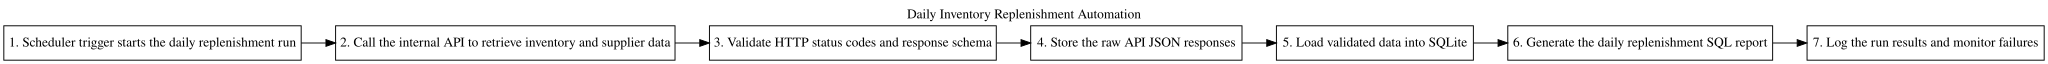

AUTO-FLOW: Passed - step count, required concepts, and order validated.


True

In [ ]:
# SQL DEVELOPER WORKSPACE
automation_steps = [
    "Scheduler trigger starts the daily replenishment run",
    "Call the internal API to retrieve inventory and supplier data",
    "Validate HTTP status codes and response schema",
    "Store the raw API JSON responses",
    "Load validated data into SQLite",
    "Generate the daily replenishment SQL report",
    "Log the run results and monitor failures"
]
auto_groups=[
    [["cron","scheduler"]], [["api"]], [["http"],["schema"]], [["json"]], [["sqlite"]], [["sql"],["report"]], [["log","monitor"]]
]
validate_sequence("AUTO-FLOW",automation_steps,auto_groups,"Daily Inventory Replenishment Automation")

### Expected Output
- Exactly seven ordered steps.
- Required concepts appear in the correct positions.
- A visible left-to-right automation diagram.
- Overall status: `Passed`.

## AUTO-REPORT - Scheduled inventory exception summary
**Business requirement - Replenishment Operations Manager:** Generate the SQL report used by the scheduled workflow to summarize all open inventory exceptions by exception type and severity.

In [ ]:
# SQL DEVELOPER WORKSPACE
auto_report_query = """
SELECT
    exception_type,
    severity,
    COUNT(*) AS open_cases,
    COALESCE(SUM(expected_value), 0.0) AS total_expected_value,
    COALESCE(SUM(actual_value), 0.0) AS total_actual_value
FROM inventory_exceptions
WHERE resolution_status = 'OPEN'
GROUP BY
    exception_type,
    severity
ORDER BY
    CASE severity
        WHEN 'CRITICAL' THEN 1
        WHEN 'HIGH' THEN 2
        WHEN 'MEDIUM' THEN 3
        WHEN 'LOW' THEN 4
        ELSE 5
    END,
    open_cases DESC,
    exception_type ASC;
"""

validate_sql("AUTO-REPORT",auto_report_query)

,exception_type,severity,open_cases,total_expected_value,total_actual_value
0,MISSING_RECEIPT,CRITICAL,73,6003.0,0.0
1,LOW_STOCK_REORDER,CRITICAL,53,2142.0,473.0
2,LOW_STOCK_REORDER,HIGH,80,3622.0,2671.0
3,SHORT_RECEIPT,HIGH,80,6781.0,5870.0
4,DUPLICATE_SUPPLIER_REFERENCE,HIGH,14,14.0,28.0
5,DAMAGE_SPIKE,HIGH,5,100.0,145.0
6,OVER_RECEIPT,MEDIUM,61,5296.0,5678.0
7,LATE_RECEIPT,MEDIUM,39,78.0,173.0
8,PENDING_TRANSFER,MEDIUM,6,12.0,84.0


,Validation,Passed,Actual
0,Exact columns,True,"['exception_type', 'severity', 'open_cases', '..."
1,Expected row count,True,9
2,Stable first row / key result,True,"{'exception_type': 'MISSING_RECEIPT', 'severit..."


AUTO-REPORT: Passed - columns, row count, and stable key result validated.


True

### Expected Output
- **Required columns:** `exception_type`, `severity`, `open_cases`, `total_expected_value`, `total_actual_value`
- **Expected row count:** **9**
- **Stable first row / key result:** `exception_type` = `MISSING_RECEIPT`, `severity` = `CRITICAL`, `open_cases` = `73`, `total_expected_value` = `6003.0`, `total_actual_value` = `0.0`
- **Validation:** exact columns, exact row count, and the stable first-row/key-result values must all match.
- **Status:** `Passed` only when all checks succeed; otherwise `Needs Review`.

**Hint:** Filter `resolution_status='OPEN'`, aggregate counts and expected/actual values, and order by operational severity before case volume.


## AUTO-CRON - Cron-ready schedules
Provide one five-field cron expression for each scenario:
1. Daily at 8 AM, 12 PM, and 4 PM.
2. Every weekday at 5 PM.
3. Every day at midnight.
4. Every Sunday at 2 AM.

These expressions are design outputs only; a Colab runtime cannot remain active as a permanent scheduler after it stops.

In [ ]:
# SQL DEVELOPER WORKSPACE
cron_expressions = [
    "0 8,12,16 * * *",
    "0 17 * * 1-5",
    "0 0 * * *",
    "0 2 * * 0"
]

validate_cron(cron_expressions)

,Scenario,Expression,Expected,Five fields,Status
0,"Daily at 8 AM, 12 PM, and 4 PM","0 8,12,16 * * *","0 8,12,16 * * *",True,Passed
1,Every weekday at 5 PM,0 17 * * 1-5,0 17 * * 1-5,True,Passed
2,Every day at midnight,0 0 * * *,0 0 * * *,True,Passed
3,Every Sunday at 2 AM,0 2 * * 0,0 2 * * 0,True,Passed


AUTO-CRON: Passed - all four exact cron expressions validated.


True

### Expected Output
| Scenario | Validation requirement |
|---|---|
| Daily at 8 AM, 12 PM, and 4 PM | Valid exact five-field cron expression; `Passed` |
| Every weekday at 5 PM | Valid exact five-field cron expression; `Passed` |
| Every day at midnight | Valid exact five-field cron expression; `Passed` |
| Every Sunday at 2 AM | Valid exact five-field cron expression; `Passed` |

The workspace values remain blank until completed. The validator confirms the exact schedules without exposing a red runtime error.

# 7. Engineering Practices
Represent professional collaboration and safe database-change behavior as ordered, validated workflows. No Git command execution or repository creation is required.

## ENG-GIT - Git collaboration workflow
**Business requirement - Engineering Manager:** Provide the eight ordered collaboration steps used to take an inventory SQL change from requirement review to approved merge.

,Step,Concepts in correct position,Provided step
0,1,True,Read the requirement or ticket
1,2,True,Create a feature branch
2,3,True,Write the SQL change
3,4,True,Test and validate the SQL change
4,5,True,Commit the changes
5,6,True,Push the feature branch
6,7,True,Open a pull request and complete code review
7,8,True,Merge the change after approval


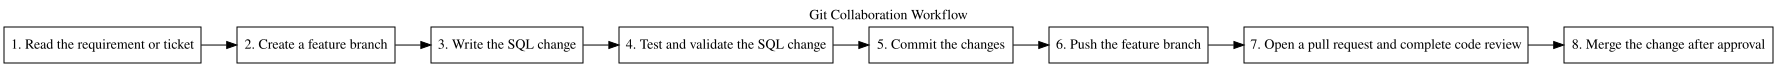

ENG-GIT: Passed - step count, required concepts, and order validated.


True

In [ ]:
# SQL DEVELOPER WORKSPACE
git_steps = [
    "Read the requirement or ticket",
    "Create a feature branch",
    "Write the SQL change",
    "Test and validate the SQL change",
    "Commit the changes",
    "Push the feature branch",
    "Open a pull request and complete code review",
    "Merge the change after approval"
]

git_groups=[
    [["requirement","ticket"]], [["feature"],["branch"]], [["sql"],["change"]], [["test"],["validat"]],
    [["commit"]], [["push"]], [["pull request"],["review"]], [["merge"],["approval","approved"]]
]
validate_sequence("ENG-GIT",git_steps,git_groups,"Git Collaboration Workflow")

### Expected Output
1. Read requirement or ticket
2. Create feature branch
3. Write SQL change
4. Test and validate
5. Commit
6. Push
7. Open pull request and complete review
8. Merge after approval

A visible workflow diagram and overall `Passed` status are required.

## ENG-CHANGE - Safe database-change workflow
**Business requirement - Engineering Manager:** Provide the eight ordered controls used to prepare, review, deploy, observe, and if needed reverse an approved database change.

,Step,Concepts in correct position,Provided step
0,1,True,Understand requirement
1,2,True,Prepare backup and rollback plan
2,3,True,Write migration or SQL change
3,4,True,Test in development
4,5,True,Complete peer review
5,6,True,Deploy approved change
6,7,True,Monitor logs and results
7,8,True,Roll back if deployment fails


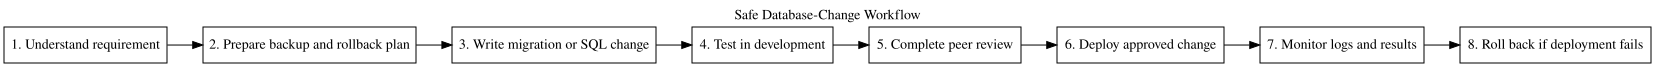

ENG-CHANGE: Passed - step count, required concepts, and order validated.


True

In [ ]:
# SQL DEVELOPER WORKSPACE
change_steps = [
    "Understand requirement",
    "Prepare backup and rollback plan",
    "Write migration or SQL change",
    "Test in development",
    "Complete peer review",
    "Deploy approved change",
    "Monitor logs and results",
    "Roll back if deployment fails"
]

change_groups=[
    [["requirement"]], [["backup"],["rollback"]], [["migration","sql"],["change","script"]],
    [["test"],["development"]], [["peer"],["review"]], [["deploy"],["approved","approval"]],
    [["monitor"],["log","result"]], [["roll back","rollback"],["fail"]]
]
validate_sequence("ENG-CHANGE",change_steps,change_groups,"Safe Database-Change Workflow")

### Expected Output
1. Understand requirement
2. Prepare backup and rollback plan
3. Write migration or SQL change
4. Test in development
5. Complete peer review
6. Deploy approved change
7. Monitor logs and results
8. Roll back if deployment fails

A visible workflow diagram and overall `Passed` status are required.

# 8. Progress Check
Review all 26 activity IDs in one dashboard. Complete work displays `Passed`; incomplete work displays `Needs Review`.

In [ ]:
progress_dashboard()

,Activity ID,Status
0,ER-1,Passed
1,API-Q1,Passed
2,API-Q2,Passed
3,API-Q3,Passed
4,API-Q4,Passed
5,API-Q5,Passed
6,Q1,Passed
7,Q2,Passed
8,Q3,Passed
9,Q4,Passed


,Status,Count
0,Passed,26


Completed activities: 26 / 26


,Activity ID,Status
0,ER-1,Passed
1,API-Q1,Passed
2,API-Q2,Passed
3,API-Q3,Passed
4,API-Q4,Passed
5,API-Q5,Passed
6,Q1,Passed
7,Q2,Passed
8,Q3,Passed
9,Q4,Passed
